# Process B – visual analysis (README)

**What this notebook is:** plots to *see* process B (a penicillin-fermentation-style process; 40 labelled batches, 40 test batches, 20 variables, 5001 timesteps each, no missing values). Colours are the same in every plot: **grey = accepted, orange = rejected, blue = test (unlabelled)**. Where it matters which rejected batch is which (there are only 5), each one gets its own colour *and* line style / marker. Sections follow the same order as the process A notebook; the key findings are here.

## Key findings

1. **Only 5 of 40 batches are rejected** (`B_017, B_032, B_049, B_075, B_078`). All batches have exactly 5001 timesteps. Four variables are exactly constant (`hot_cold_switch`, `feed_substate_concentration`, `cooling_water_temperature`, `heating_water_temperature`); `base_flow` and `acid_flow` are tiny but *not* constant and are kept in the analysis. (§1)
2. **All batches follow the same recipe:** substrate is consumed until t ≈ 2000, biomass and oxygen demand rise, then the feed switches on (t ≈ 1900–2400) and penicillin accumulates. Accepted and rejected trajectories overlap almost everywhere – you cannot spot a rejected batch by eye in most variables. (§2)
3. **`aeration_rate` gives the rejected batches away.** In every rejected batch it **drops for the same window, t = 500–1250, by 1.6–2.3 units, then recovers**. Accepted batches keep it flat (range ≤ 0.031). The within-batch range separates the classes perfectly: accepted ≤ 0.031, rejected 1.56–2.34 (gap ≈ 1.5), AUC = 1.00. No other variable comes close. (§4, §7, §9)
4. **Test set:** the same rule flags **5 of 40 test batches** (`B_008, B_041, B_052, B_060, B_064`, ranges 1.70–2.36), the same share as calibration. Nothing lies in the gap (the closest are `B_016`, `B_059`, `B_069` at 0.032–0.035, clearly on the accepted side), so the call is unambiguous. (§7)
5. **No drift over the campaign:** rejected batches are spread over the batch numbers and the test batches are interleaved with the calibration ones. (§6)
6. **Phase timing is not the cause.** Feed-start time varies between batches (≈ 1930–2410), but rejected batches are inside the accepted range; aligning batches on feed start tightens the curves but reveals no extra difference. (§12.1)
7. **Dissolved oxygen after the growth phase is a weaker, secondary hint:** in rejected batches the plateau sits in a narrow band (~1.087–1.100) while accepted batches range 1.05–1.13 – but accepted batches overlap that band, so it does not separate the classes. (§12.2)
8. **End-of-batch yield does not discriminate:** final penicillin and biomass of rejected batches sit within the accepted spread. (§12.2)
9. **Effect of the aeration drop on other variables.** Measured as the change in z-score (vs. the accepted batches) between the pre-window baseline and the drop window t = 500–1250, and compared with what accepted batches show by chance. **Only `dissolved_oxygen` reacts**: it steps down when the drop starts and back up when it ends, in all 5 rejected batches (Δz −0.6 to −0.9, i.e. about −0.003 to −0.008 in raw units; accepted batches' own spread of window means is 0.006). That is physically plausible (less air, less oxygen), but it is of the same size as the largest random shifts in accepted batches (95th percentile 0.61, max 0.81), so it is a *consistent but weak* signal. `biomass_concentration`, `dissolved_co2`, `substrate_concentration`, `penicillin_concentration`, `ph`, `reaction_heat`, `water_flow_rate`, `reactor_temperature`, `fermentation_volume` show no effect (|Δz| ≤ 0.3, well inside the accepted range); `agitator_power` and `feed_temperature` move by as much as accepted batches do. The drop has no visible knock-on effect on biomass or product formation either in the window or afterwards. (§12.3)
10. **Calibration and test look alike** (batch means, feed start, initial volume/substrate, final penicillin), so a rule learnt on calibration should transfer. At t = 0, 14 of 20 variables are identical in every batch; the few test values outside the calibration min–max are small excesses. (§11)

## Caveats
- With 5 rejected batches, any statistic other than the aeration drop is very uncertain. All numbers are in-sample; no model was fitted.
- The aeration drop appears in all 5 rejected batches, so it is a strong rule, but we do not know whether *other* rejection causes exist that are absent from the calibration set.

*Data is read through a parquet cache in `/home/renku/work/parquet_cache/` (outside the repo).*

---
## 0. Setup & data
Loads the data, defines the colour palette and the per-batch summaries (mean, standard deviation, range, final value, feed-start time) used throughout. All batches have the same length, so time is kept in raw timesteps.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,
                     "axes.titleweight":"bold","axes.titlesize":10,"axes.labelsize":9,"legend.frameon":False,"legend.fontsize":9,
                     "axes.formatter.useoffset":False,"axes.formatter.limits":(-7,7)})   # plain numbers on the axes, no "1e-6 + 4.99996" offsets

# Colour-blind-safe palette (checked for protan/deutan/tritan separation): grey = accepted, orange = rejected, blue = test
ACC,REJ,TEST,INK="#8a8f98","#eb6834","#2a78d6","#333333"
PAL={"accepted":ACC,"rejected":REJ}
# for highlighting individual batches: colour AND line style / marker differ, so identity never relies on colour alone
HL_COL=["#000000","#d55181","#008300","#6250d6","#a6761d"]; HL_LS=["-","--","-.",":",(0,(5,1,1,1))]; HL_MK=["o","s","^","D","v"]
WIN_COL="#f0e442"   # yellow shading for time windows
REJ_MED="#6250d6"   # violet: rejected median, clearly different from the orange single batches
MED_KW=dict(color="#555555",ls="--")   # accepted median when individual batches are drawn on top

# legend helpers
def dot(c,l,m="o",**k): return Line2D([],[],marker=m,ls="",color=c,label=l,markersize=7,**k)
def hollow(c,l): return Line2D([],[],marker="o",ls="",markerfacecolor="none",markeredgecolor=c,label=l,markersize=7)
def line(c=None,l=None,lw=2,label=None,**k): return Line2D([],[],color=k.pop("color",c),label=label or l,lw=lw,**k)
def patch(c,l,a=.4): return Patch(color=c,alpha=a,label=l)
CLASS_LEG=[dot(ACC,"accepted"),dot(REJ,"rejected")]
def top_legend(fig,h,y=1.0,ncol=None,**k): fig.legend(handles=h,loc="lower center",bbox_to_anchor=(.5,y),ncol=ncol or len(h),frameon=False,fontsize=10,**k)
def legend_axis(ax,h,**k): ax.axis("off"); ax.legend(handles=h,loc="center",fontsize=11,**k)
OFF_LEG=Line2D([],[],marker="^",ls="",color="#9a9a9a",markeredgecolor="k",markersize=8,label="▲ ▼ ◀ ▶ = batch beyond the axis, drawn at the edge")

# ---- readable axes: zoom to the bulk of the batches, show extreme batches as triangles at the edge
PLAIN=FuncFormatter(lambda v,_: f"{v:.6g}")
def plain_log(ax,axis="y"):
    """log axis with plain tick labels (0.01, 0.02, 0.05 ... instead of 2×10⁻²)"""
    A=ax.yaxis if axis=="y" else ax.xaxis
    A.set_major_locator(LogLocator(base=10,subs=(1,2,5))); A.set_major_formatter(PLAIN); A.set_minor_formatter(NullFormatter())
def bulk_lims(v,log=False,k=1.5,force=False):
    """axis limits covering the bulk of the values -> (lo, hi, zoomed?). Zooms only when a few extreme values would squash the rest."""
    v=np.asarray(v,float); v=v[np.isfinite(v)]
    if log: v=v[v>0]
    t=np.log10(v) if log else v
    p5,p95=np.percentile(t,[5,95]); full=np.ptp(t) or 1; sp=(p95-p5) or full
    if full<=4*sp and not force: lo,hi,zoom=t.min(),t.max(),False
    else: lo,hi,zoom=max(t.min(),p5-k*sp),min(t.max(),p95+k*sp),True
    pad=.06*((hi-lo) or 1); lo,hi=lo-pad,hi+pad
    return (10**lo,10**hi,zoom) if log else (lo,hi,zoom)
def scatter_clip(ax,x,y,xl,yl,color,s=30,marker="o",hollow_=False,alpha=1,zorder=3):
    """scatter inside the limits; points outside are drawn as triangles at the edge pointing to where they are. Returns (x, y, any clipped)"""
    x=np.asarray(x,float); y=np.asarray(y,float); cx=np.clip(x,*xl); cy=np.clip(y,*yl); inn=(x==cx)&(y==cy)
    kw=dict(facecolors="none",edgecolors=color) if hollow_ else dict(color=color)
    ax.scatter(x[inn],y[inn],s=s,marker=marker,alpha=alpha,zorder=zorder,**kw)
    mk=np.where(y>yl[1],"^",np.where(y<yl[0],"v",np.where(x>xl[1],">","<")))
    for m_ in "^v<>":
        sel=(~inn)&(mk==m_)
        if sel.any(): ax.scatter(cx[sel],cy[sel],marker=m_,color=color,edgecolors="k",linewidths=.6,s=max(s*1.8,45),zorder=zorder+2,clip_on=False)
    return cx,cy,bool((~inn).any())
def class_box(ax,values,classes,ylabel,log="auto",zoom=True):
    """box + one dot per batch, accepted vs rejected. log='auto' uses a log axis when values span > 50x.
    With zoom, the axis covers the bulk of the batches and extreme batches are drawn as triangles at the edge
    (with their number and most extreme value). Returns True if any batch was drawn at the edge."""
    v=np.asarray(values,float); c=np.asarray(classes)
    if log=="auto": log=bool((v>0).all() and v.max()/v.min()>50)
    if log and not (v>0).all(): log=False
    d=pd.DataFrame({"v":v,"class":c})
    sns.boxplot(data=d,x="class",y="v",hue="class",legend=False,palette=PAL,order=["accepted","rejected"],ax=ax,width=.5,fliersize=0,boxprops=dict(alpha=.35),whis=(0,100) if not zoom else 1.5)
    lo,hi,_=bulk_lims(v,log) if zoom else (*bulk_lims(v,log,k=1e9)[:2],False)
    rng_=np.random.default_rng(0); clipped=False
    for i,k in enumerate(["accepted","rejected"]):
        m=c==k; x=i+rng_.uniform(-.18,.18,m.sum()); vv=v[m]
        _,_,cl=scatter_clip(ax,x,vv,(-1,2),(lo,hi),PAL[k],s=16,alpha=.85); clipped|=cl
        for sel,edge,va,dy,ext in ((vv>hi,hi,"top",-7,np.max),(vv<lo,lo,"bottom",7,np.min)):   # label sits inside the axis, next to the triangles
            if sel.any(): ax.annotate(f"{sel.sum()} beyond ({'max' if ext is np.max else 'min'} {ext(vv[sel]):.4g})",(i,edge),xytext=(0,dy),textcoords="offset points",
                                      fontsize=7,va=va,ha="center",color=INK,bbox=dict(boxstyle="round,pad=.15",fc="white",ec="none",alpha=.85),zorder=6)
    if log: ax.set_yscale("log"); plain_log(ax)
    ax.set_ylim(lo,hi); ax.set_xlim(-.5,1.5); ax.set_xlabel("class"); ax.set_ylabel(ylabel+(" (log scale)" if log and "log" not in ylabel else ""))
    return clipped

ROOT=Path("/home/renku/work/input-data/Project 2 - BRPMM"); CACHE=Path("/home/renku/work/parquet_cache"); CACHE.mkdir(exist_ok=True)
def read_cached(csv,name):
    pq=CACHE/f"{name}.parquet"
    if pq.exists() and pq.stat().st_mtime>=Path(csv).stat().st_mtime: return pd.read_parquet(pq)
    df=pd.read_csv(csv); df.to_parquet(pq,index=False); return df
def load(p):
    b=ROOT/f"process {p}"
    cal=read_cached(b/"calibration data/calibration_data.csv",f"{p}_cal"); lab=pd.read_csv(b/"calibration data/calibration_labels.csv")
    test=read_cached(b/"test data/test_data.csv",f"{p}_test")
    for d in (cal,test): d["t"]=d.groupby("batch_id").cumcount(); d["tn"]=d.t/d.groupby("batch_id").t.transform("max")  # tn = normalised time 0..1
    return cal.merge(lab,on="batch_id"),lab,test
def robust_ylim(a,lo=1,hi=99,pad=.15):
    l,h=np.nanpercentile(a,[lo,hi]); d=(h-l) or 1; return l-pad*d,h+pad*d
bnum=lambda ids:np.array([int(b.split("_")[1]) for b in ids])

GPAL={"accepted":ACC,"rejected":REJ,"test":TEST}; GORDER=["accepted","rejected","test"]
def length_panels(ax_hist,ax_box,n_cal,n_test,y,bins,name_below=None):
    """middle: batch-length histogram, one filled bar per group side by side; right: box + one dot per batch for each group"""
    grp={"accepted":n_cal[y.reindex(n_cal.index)=="accepted"],"rejected":n_cal[y.reindex(n_cal.index)=="rejected"],"test":n_test}
    ax_hist.hist([grp[k] for k in GORDER],bins=bins,color=[GPAL[k] for k in GORDER],label=["accepted","rejected","test (unlabelled)"],rwidth=.9)
    ax_hist.set(title="Distribution of batch length",xlabel="timesteps per batch",ylabel="number of batches"); ax_hist.legend(loc="upper left")
    d=pd.concat([pd.DataFrame({"length":v.values,"group":k,"batch":v.index}) for k,v in grp.items()])
    sns.boxplot(data=d,x="group",y="length",hue="group",legend=False,palette=GPAL,order=GORDER,ax=ax_box,width=.5,fliersize=0,boxprops=dict(alpha=.35))
    sns.stripplot(data=d,x="group",y="length",hue="group",legend=False,palette=GPAL,order=GORDER,ax=ax_box,size=4.5,alpha=.85,jitter=.2)
    ax_box.set(title="Batch length per group (one dot = one batch)",xlabel="batch group",ylabel="timesteps per batch")
    ax_box.set_xticks(range(3),[f"{k}\n(n = {len(grp[k])})" for k in GORDER])
    ax_box.set_xlim(-.5,2.95)
    h=[dot(GPAL[k],f"{k} batch" if k!="test" else "test batch (unlabelled)") for k in GORDER]+[patch("#999","box = middle 50 % of batches"),line("#555","line in box = median",lw=1.5),line("#555","whiskers = range without outliers",lw=.8)]
    if name_below is not None: h.append(line("#999",f"named = calibration batch shorter\nthan {name_below} steps",lw=.6))
    ax_box.legend(handles=h,loc="upper left",bbox_to_anchor=(1.01,1),fontsize=8.5,title="Legend",title_fontproperties=dict(weight="bold",size=9))
    if name_below is not None:   # name the unusually short batches
        lo,hi=ax_box.get_ylim(); gap=.045*(hi-lo)
        for k in ["accepted","rejected"]:   # calibration batches only (the ones discussed in the README)
            sh=grp[k][grp[k]<name_below].sort_values(); prev=-np.inf
            for b,v in sh.items():   # spread labels vertically so they never overlap; a thin line points to the dot
                ty=max(v,prev+gap); prev=ty; x=GORDER.index(k)
                ax_box.annotate(f"{b} ({v})",xy=(x+.08,v),xytext=(x+.3,ty),fontsize=8,va="center",arrowprops=dict(arrowstyle="-",color="#999",lw=.6))

from scipy.ndimage import uniform_filter1d
cal,lab,test=load("B")
ALL=[c for c in cal.columns if c not in("batch_id","t","tn","label")]
CONST=[v for v in ALL if cal[v].nunique()==1]; V=[v for v in ALL if v not in CONST]
y=lab.set_index("batch_id").label
def wide(df,v): return df.pivot(index="batch_id",columns="t",values=v)
W={v:wide(cal,v).loc[y.index] for v in V}; WT={v:wide(test,v) for v in V}
acc=(y=="accepted").values; rej=~acc; ids=list(y.index); idt=list(WT[V[0]].index); t=W[V[0]].columns.values; yc=y.values
n_cal=cal.groupby("batch_id").size(); n_test=test.groupby("batch_id").size()
# per-batch summaries
mean=pd.DataFrame({v:W[v].mean(axis=1) for v in V}); meanT=pd.DataFrame({v:WT[v].mean(axis=1) for v in V})
sd=pd.DataFrame({v:W[v].std(axis=1) for v in V})
rng=pd.DataFrame({v:W[v].max(axis=1)-W[v].min(axis=1) for v in V}); rngT=pd.DataFrame({v:WT[v].max(axis=1)-WT[v].min(axis=1) for v in V})
end=pd.DataFrame({v:W[v].iloc[:,-1] for v in V}); endT=pd.DataFrame({v:WT[v].iloc[:,-1] for v in V})
feed_start=lambda Wd: pd.Series({b:int(Wd["feed_rate"].columns[(Wd["feed_rate"].loc[b]>.03).values][0]) for b in Wd["feed_rate"].index})
fs=feed_start(W); fst=feed_start(WT)
print(f"{len(ALL)} variables ({len(CONST)} exactly constant: {CONST}) | {len(ids)} calibration batches ({rej.sum()} rejected) | {len(idt)} test batches | 5001 timesteps each")
REJB=[b for b in ids if y[b]=="rejected"]; ACCB=[b for b in ids if y[b]=="accepted"]
RS={b:dict(color=HL_COL[i],ls=HL_LS[i],marker=HL_MK[i]) for i,b in enumerate(REJB)}   # one style per rejected batch
REJ_LEG=[line(RS[b]["color"],b,ls=RS[b]["ls"]) for b in REJB]

20 variables (4 exactly constant: ['hot_cold_switch', 'feed_substate_concentration', 'cooling_water_temperature', 'heating_water_temperature']) | 40 calibration batches (5 rejected) | 40 test batches | 5001 timesteps each


## 1. Class balance and batch length
How many batches are rejected, and does batch length play a role?
- **Left:** number of batches per class.
- **Right:** batch length for every group (accepted, rejected, test). All 80 batches have exactly 5001 timesteps, so batch length plays no role in process B.

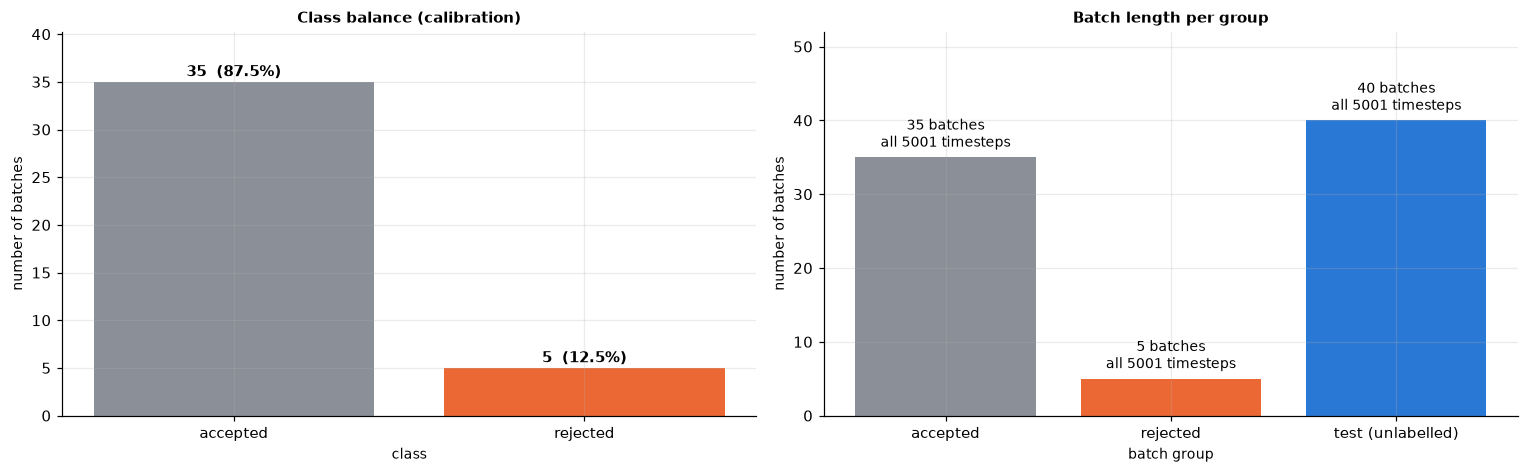

Constant in every batch (left out of all plots): hot_cold_switch, feed_substate_concentration, cooling_water_temperature, heating_water_temperature


In [2]:
fig,ax=plt.subplots(1,2,figsize=(14,4.4))
vc=y.value_counts().reindex(["accepted","rejected"]); ax[0].bar(vc.index,vc.values,color=[PAL[k] for k in vc.index])
for i,v in enumerate(vc.values): ax[0].text(i,v+.6,f"{v}  ({100*v/vc.sum():.1f}%)",ha="center",fontweight="bold")
ax[0].set(title="Class balance (calibration)",xlabel="class",ylabel="number of batches",ylim=(0,vc.max()*1.15))
# batch length: one bar per group, labelled with the (single) length found in that group
grp={"accepted":n_cal[y.reindex(n_cal.index)=="accepted"],"rejected":n_cal[y.reindex(n_cal.index)=="rejected"],"test":n_test}
ax[1].bar(GORDER,[len(grp[k]) for k in GORDER],color=[GPAL[k] for k in GORDER])
for i,k in enumerate(GORDER):
    L=sorted(grp[k].unique()); txt=f"{len(grp[k])} batches\nall {L[0]} timesteps" if len(L)==1 else f"{len(grp[k])} batches\n{min(L)}–{max(L)} timesteps"
    ax[1].text(i,len(grp[k])+.8,txt,ha="center",va="bottom",fontsize=9)
ax[1].set(title="Batch length per group",xlabel="batch group",ylabel="number of batches",ylim=(0,max(len(v) for v in grp.values())*1.3))
ax[1].set_xticks(range(3),["accepted","rejected","test (unlabelled)"])
plt.tight_layout(); plt.show()
print("Constant in every batch (left out of all plots):",", ".join(CONST))

## 2. Every variable over time
Do accepted and rejected batches follow different trajectories? Curves are smoothed (25-timestep moving average) so that noisy variables such as `dissolved_co2` show the trend instead of a solid band of noise; the noise itself is compared in §4. **Grey band** = middle 80 % of accepted batches, **grey dashed line** = accepted median (both computed on the smoothed curves), each **rejected batch** has its own colour and line style. Constant variables are left out.

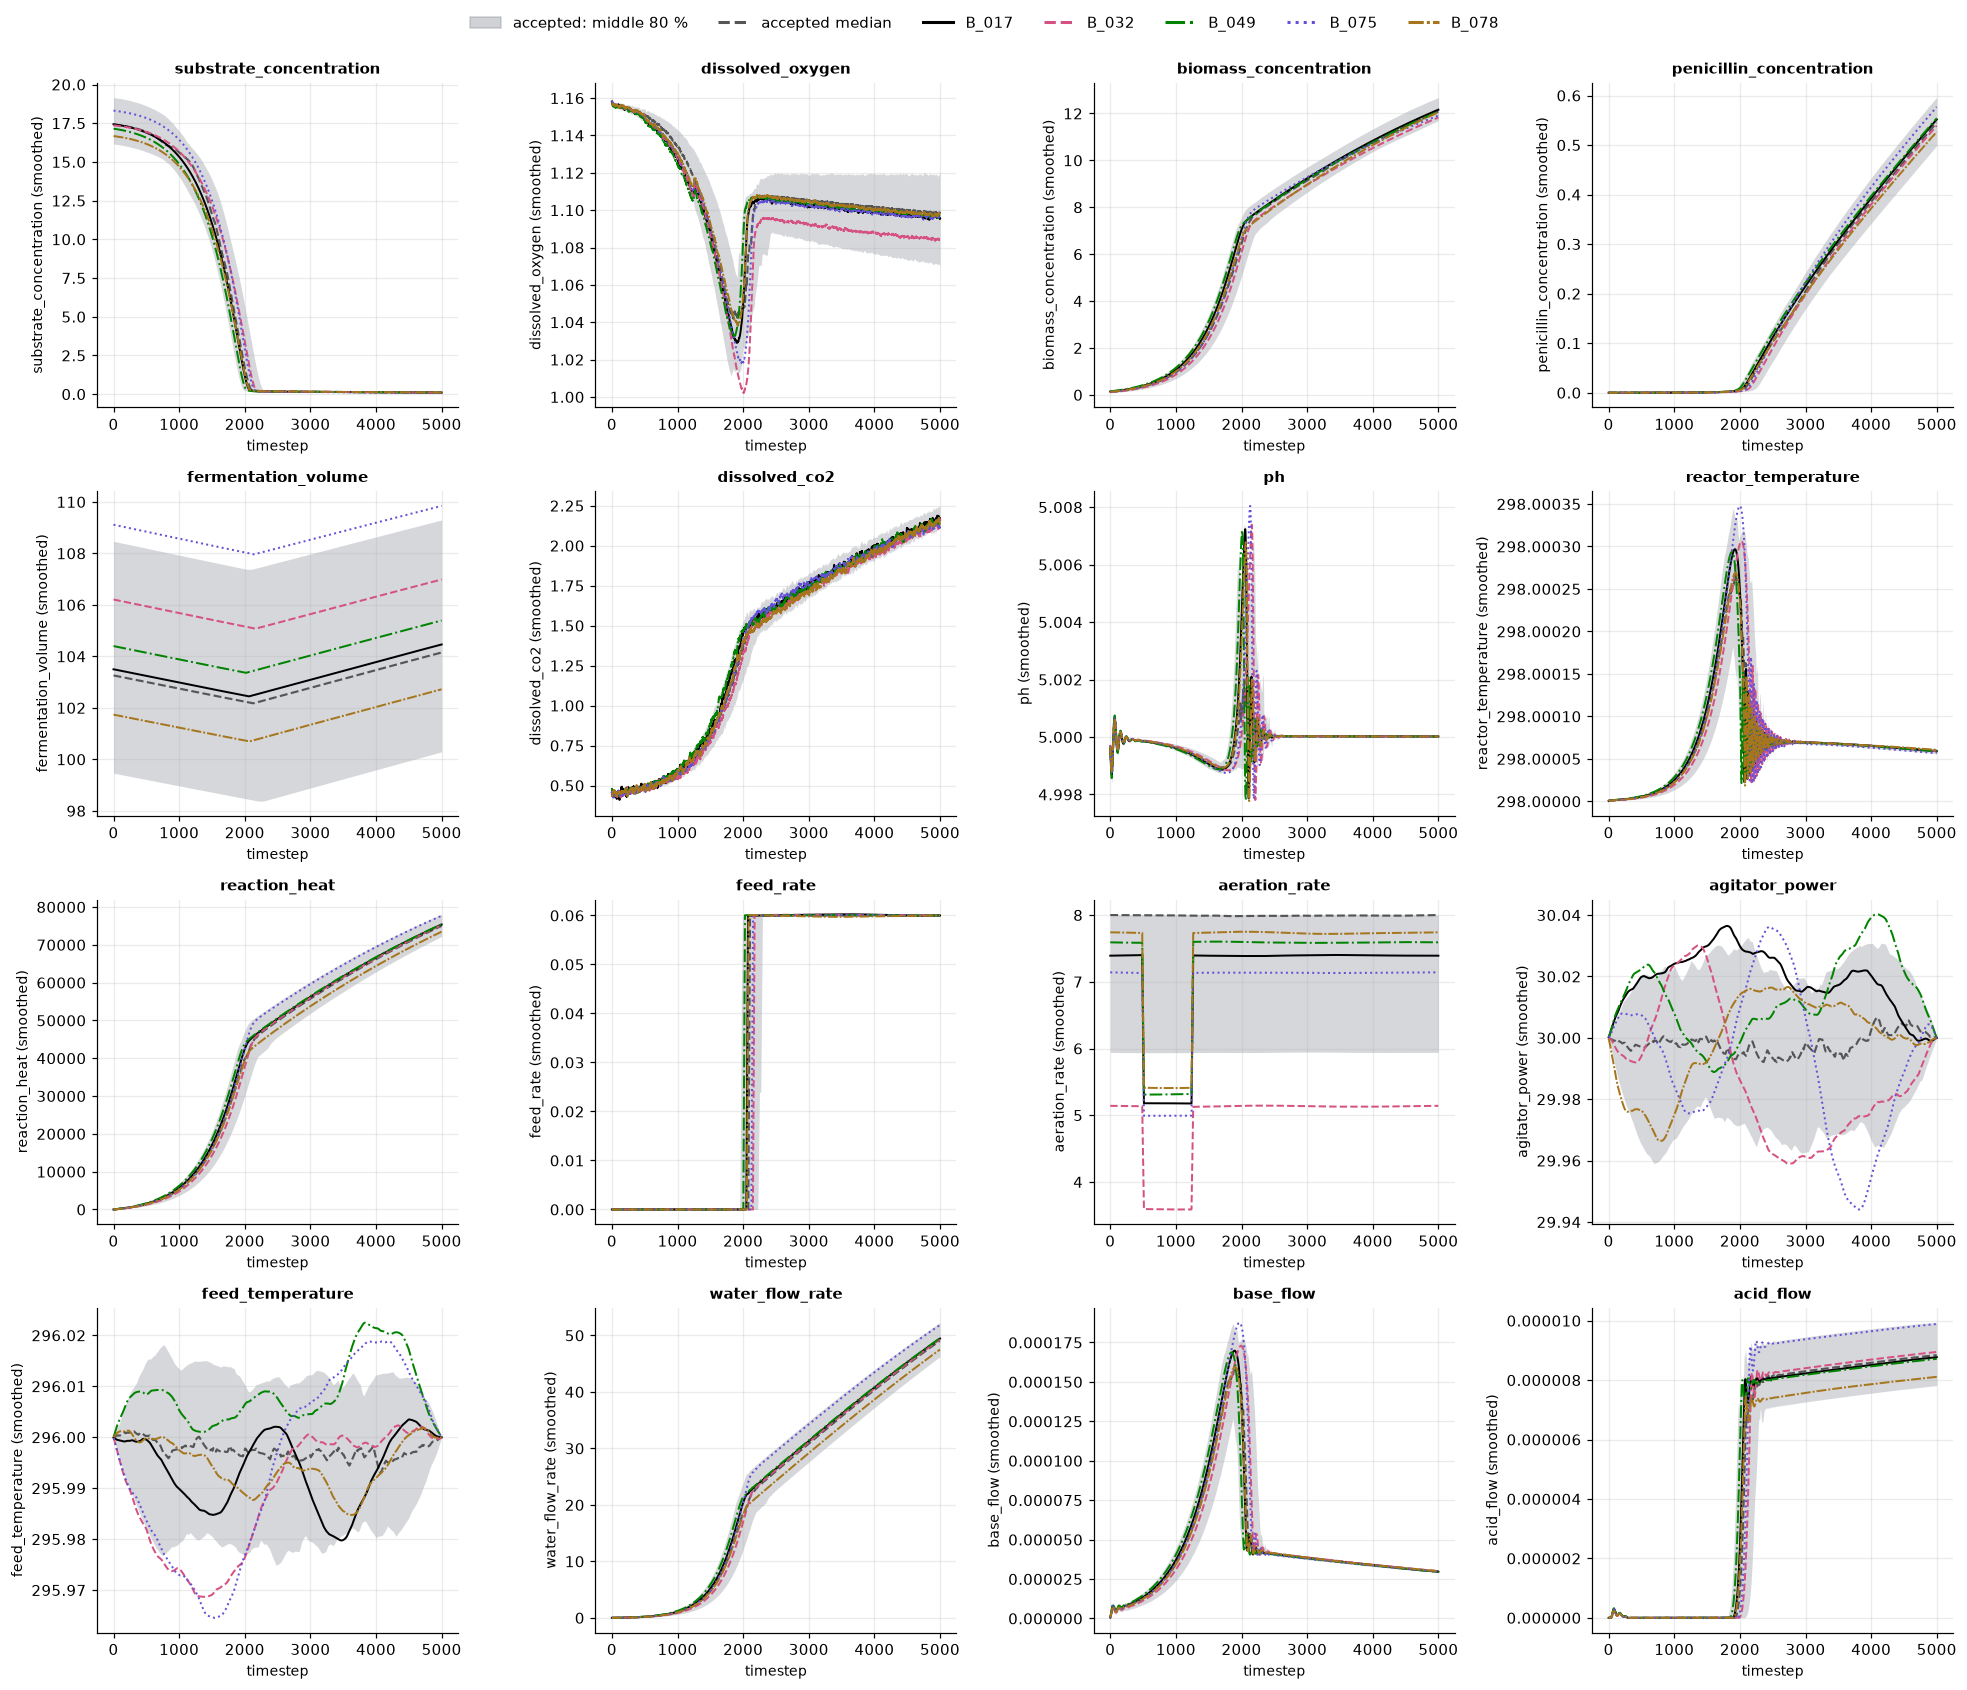

In [3]:
fig,axs=plt.subplots(4,4,figsize=(18,15))
for ax,v in zip(axs.ravel(),V):
    X=uniform_filter1d(W[v].values,25,axis=1,mode="nearest")   # smoothed: one row per batch
    ax.fill_between(t,np.percentile(X[acc],10,axis=0),np.percentile(X[acc],90,axis=0),color=ACC,alpha=.35,lw=0)
    ax.plot(t,np.median(X[acc],0),lw=1.4,**MED_KW)
    for b in REJB: ax.plot(t,X[ids.index(b)],color=RS[b]["color"],ls=RS[b]["ls"],lw=1.3)
    ax.set(title=v,xlabel="timestep",ylabel=f"{v} (smoothed)")
top_legend(fig,[patch(ACC,"accepted: middle 80 %"),line(label="accepted median",**MED_KW)]+REJ_LEG,ncol=7)
plt.tight_layout(); plt.show()

## 3. Does the *level* of a variable separate the classes?
One dot per batch = the batch's mean over the whole run; boxes show the spread of each class. If the orange dots sit outside the grey ones, the level alone flags those batches. When a few extreme batches would squash the others, the axis is zoomed to the bulk and those batches are drawn as **triangles at the edge** (▲ above, ▼ below) with their number and most extreme value.

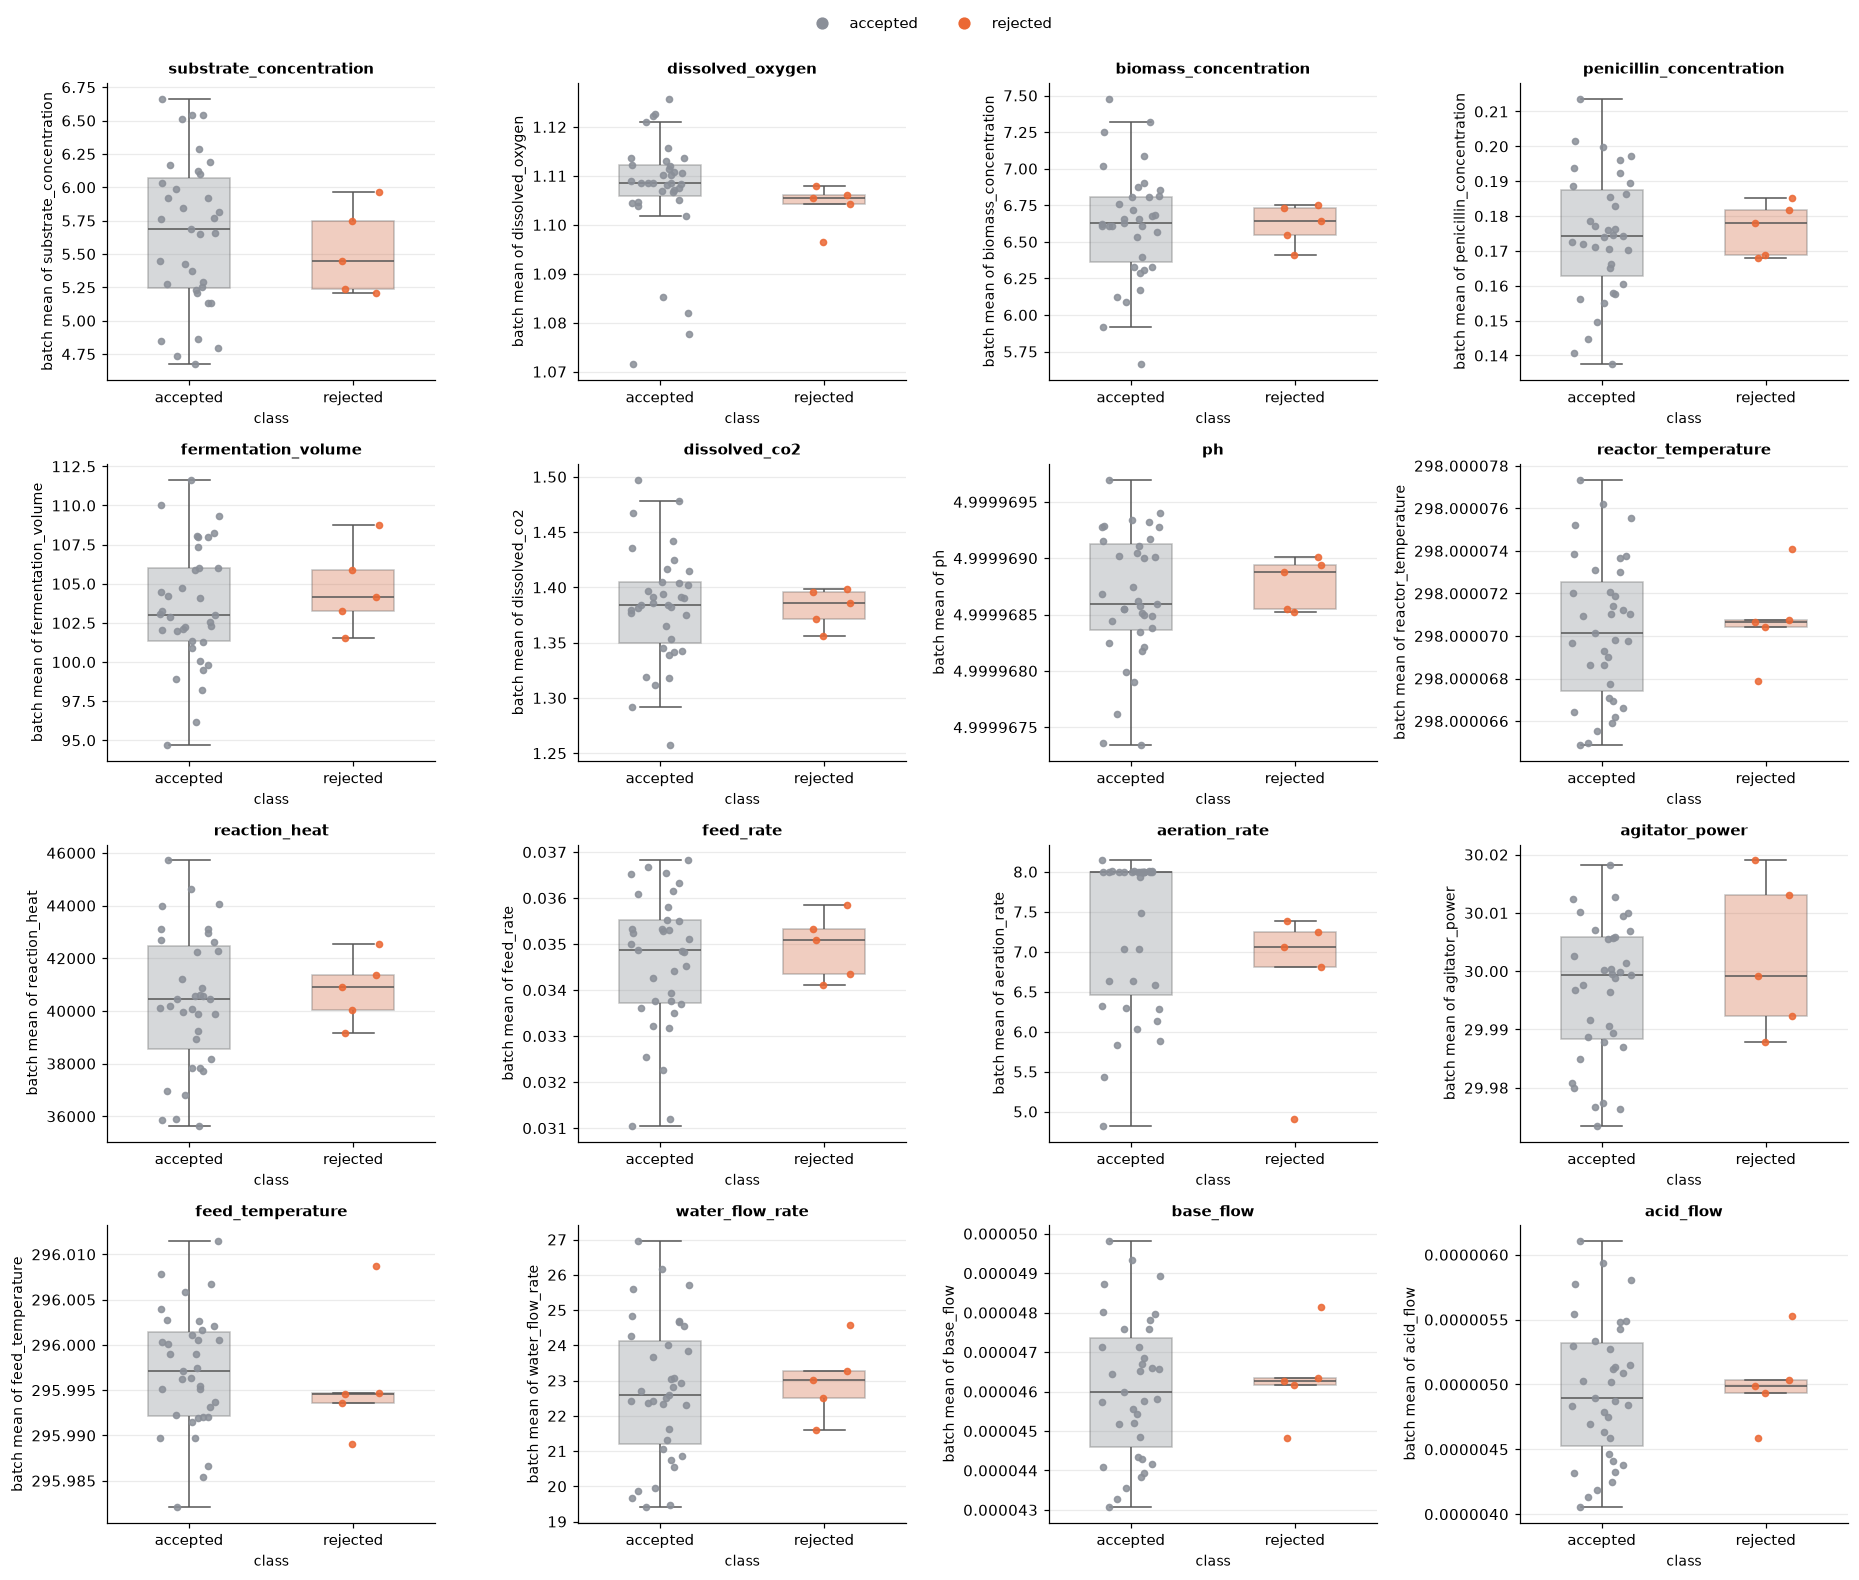

In [4]:
fig,axs=plt.subplots(4,4,figsize=(17,14)); off=False
for ax,v in zip(axs.ravel(),V):
    off|=class_box(ax,mean[v].values,yc,f"batch mean of {v}"); ax.set_title(v)
plt.tight_layout(); top_legend(fig,CLASS_LEG+[OFF_LEG]*off); plt.show()

## 4. Does the *variability* of a variable separate the classes?
One dot per batch = the within-batch standard deviation (log scale where values span a wide range). In process B the variables follow a recipe, so the std also reflects how much a variable moves during the run. A clearly higher orange cloud means rejected batches move more in that variable. When a few extreme batches would squash the others, the axis is zoomed to the bulk and those batches are drawn as **triangles at the edge** (▲ above, ▼ below) with their number and most extreme value.

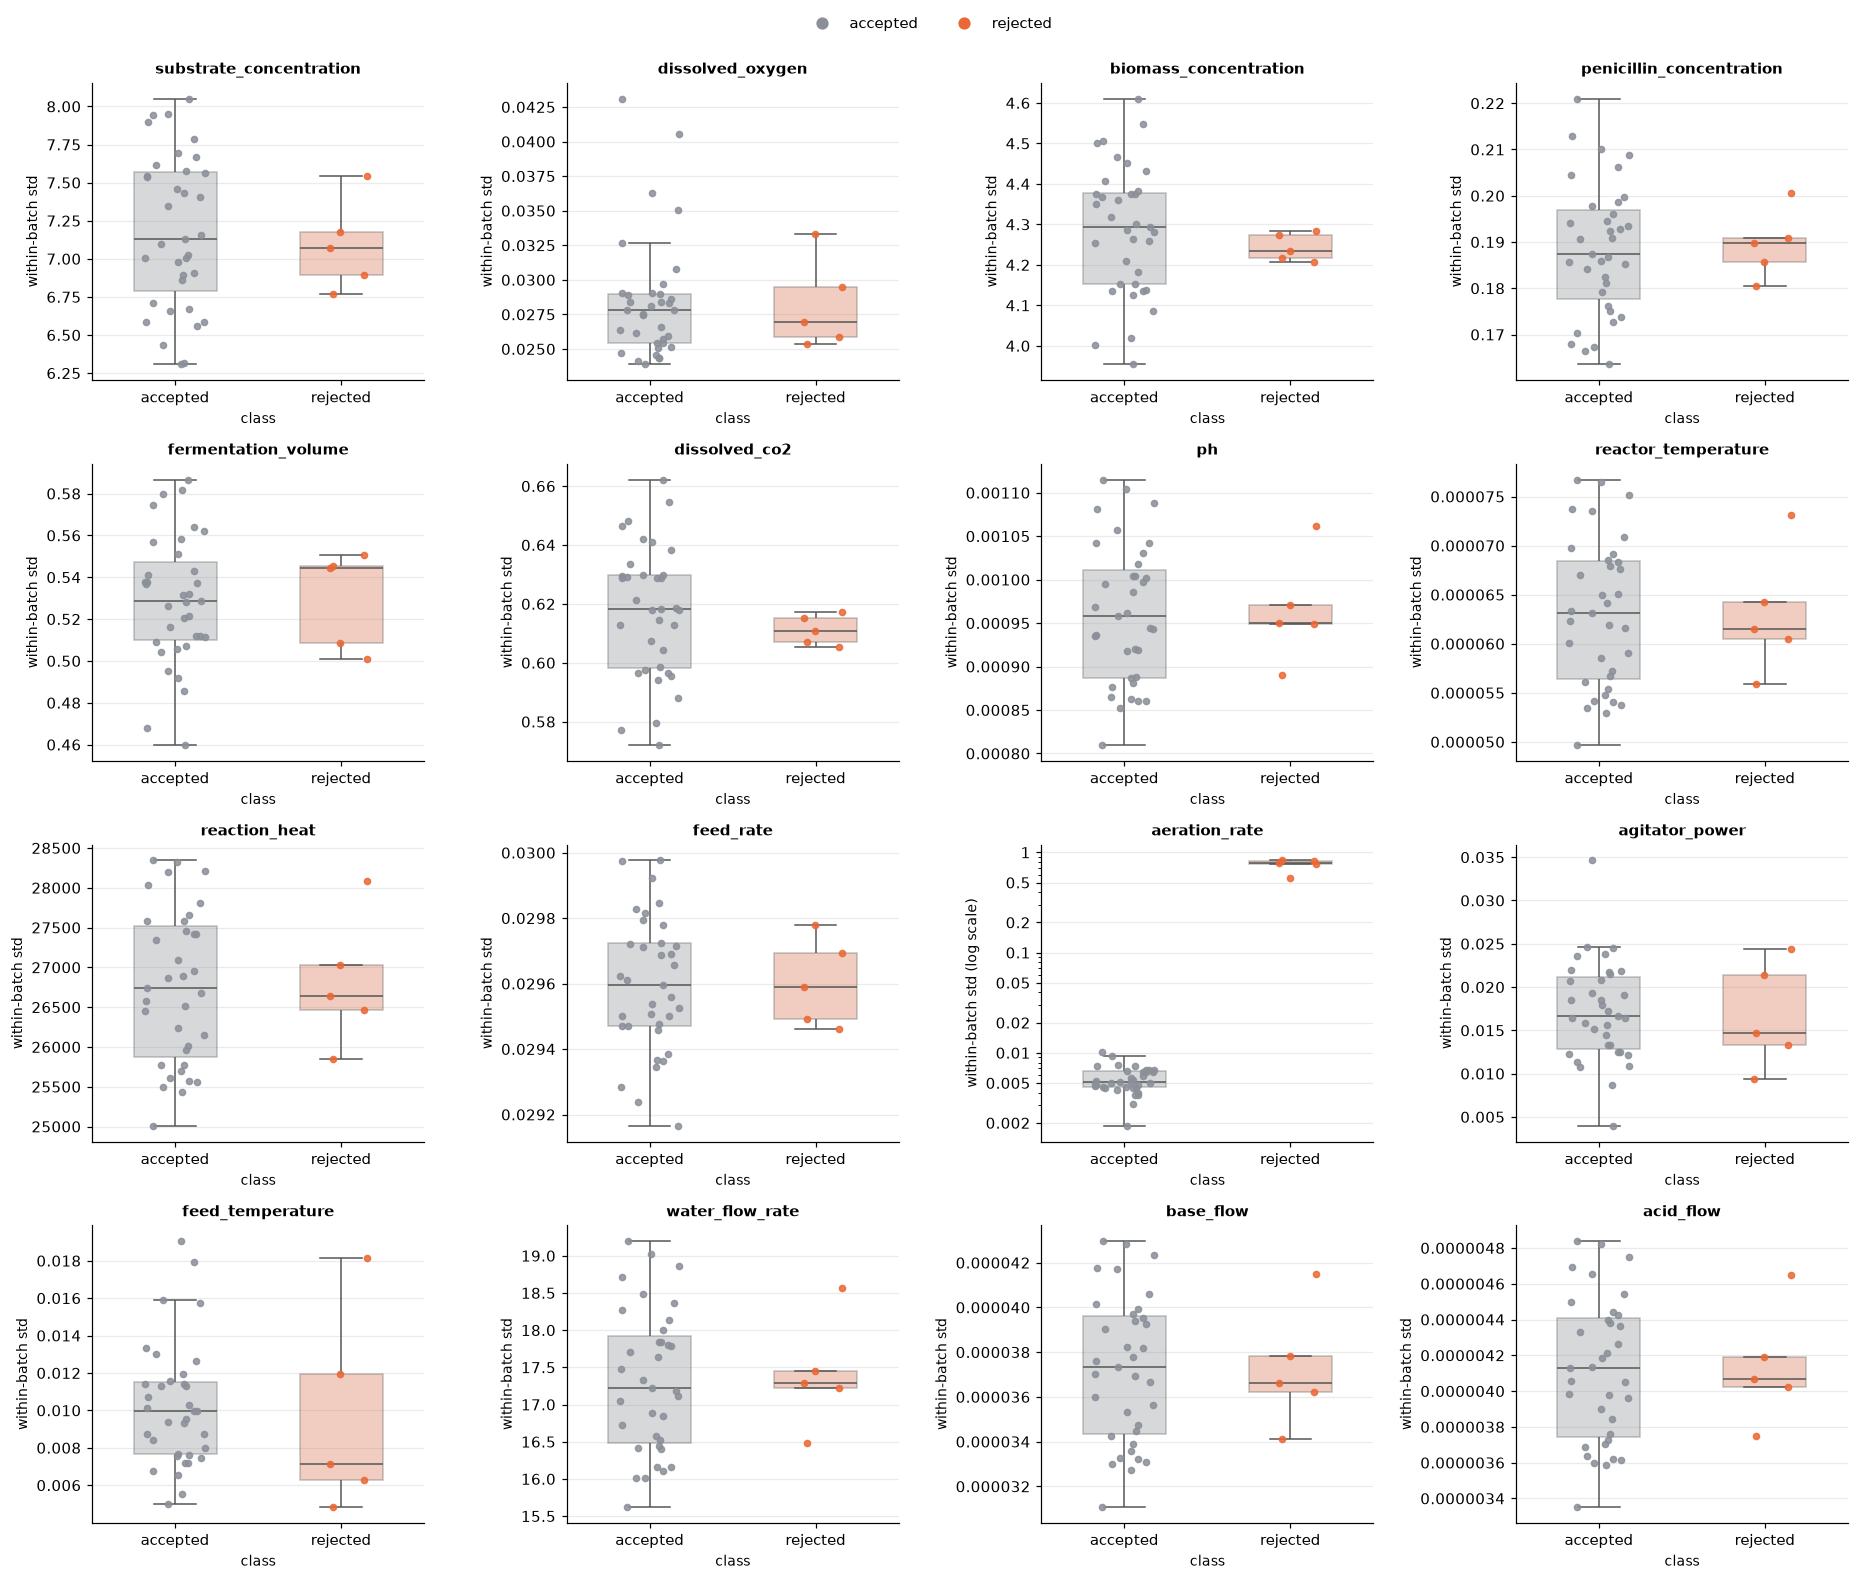

In [5]:
fig,axs=plt.subplots(4,4,figsize=(17,14)); off=False
for ax,v in zip(axs.ravel(),V):
    off|=class_box(ax,sd[v].values,yc,"within-batch std",log="auto"); ax.set_title(v)
plt.tight_layout(); top_legend(fig,CLASS_LEG+[OFF_LEG]*off); plt.show()

## 5. Which batches are outliers, and in which variable?
Each cell = |batch value − accepted centre| / threshold, where the threshold is the largest deviation seen among accepted batches. **Values above 1 (dark) are outside anything seen in accepted batches.** Left: batch **mean**; right: within-batch **range** (max − min). Rows: the 5 rejected batches on top, accepted below.

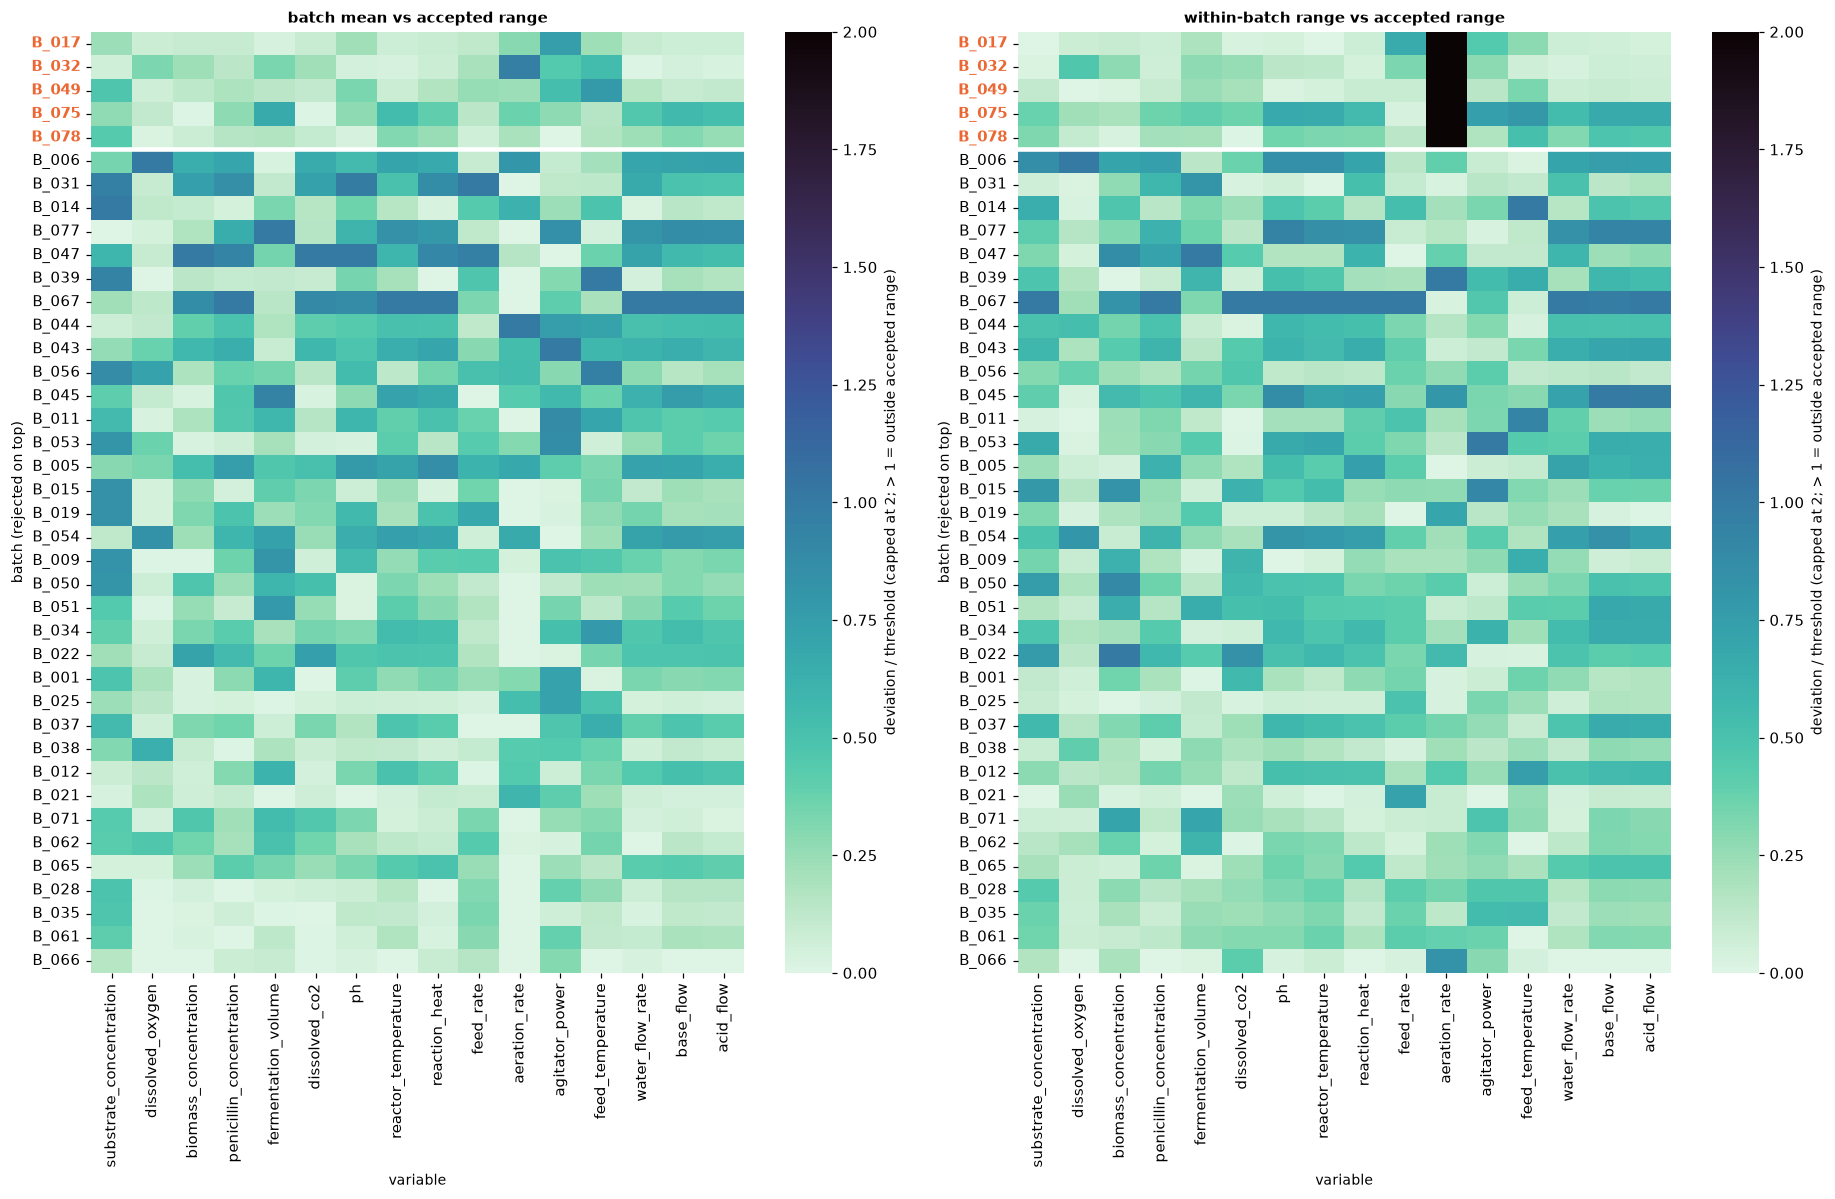

mean: rejected flagged 0/5 | accepted flagged (0 by construction) 0/35
range: rejected flagged 5/5 | accepted flagged (0 by construction) 0/35


In [6]:
def dev_of(F):
    c=F[acc].median(); th=(F[acc]-c).abs().max().replace(0,np.nan); return (F-c).abs()/th
Dm,Dr=dev_of(mean),dev_of(rng)
order=REJB+list(Dm.loc[ACCB].max(axis=1).sort_values(ascending=False).index)
fig,ax=plt.subplots(1,2,figsize=(17,11))
for a,D,name in ((ax[0],Dm,"batch mean"),(ax[1],Dr,"within-batch range")):
    sns.heatmap(D.loc[order].clip(upper=2),cmap="mako_r",vmin=0,vmax=2,ax=a,cbar_kws=dict(label="deviation / threshold (capped at 2; > 1 = outside accepted range)"),linewidths=0)
    a.axhline(rej.sum(),color="white",lw=3); a.set_title(f"{name} vs accepted range"); a.set_xlabel("variable"); a.set_ylabel("batch (rejected on top)"); a.grid(False)
    for lbl in a.get_yticklabels():
        if lbl.get_text() in REJB: lbl.set_color(REJ); lbl.set_fontweight("bold")
plt.tight_layout(); plt.show()
for name,D in (("mean",Dm),("range",Dr)):
    f=(D>1).any(axis=1); print(f"{name}: rejected flagged {f[REJB].sum()}/{len(REJB)} | accepted flagged (0 by construction) {f[ACCB].sum()}/{len(ACCB)}")

## 6. Batch order: drift over the campaign?
If the process drifted (sensor ageing, raw-material lots), batch number would show structure.
- **Top:** where accepted, test and rejected batches fall in the batch sequence (one tick per batch).
- **Middle:** rolling share of rejected batches (dashed = overall rate).
- **Bottom grid:** batch mean of every variable against batch number.

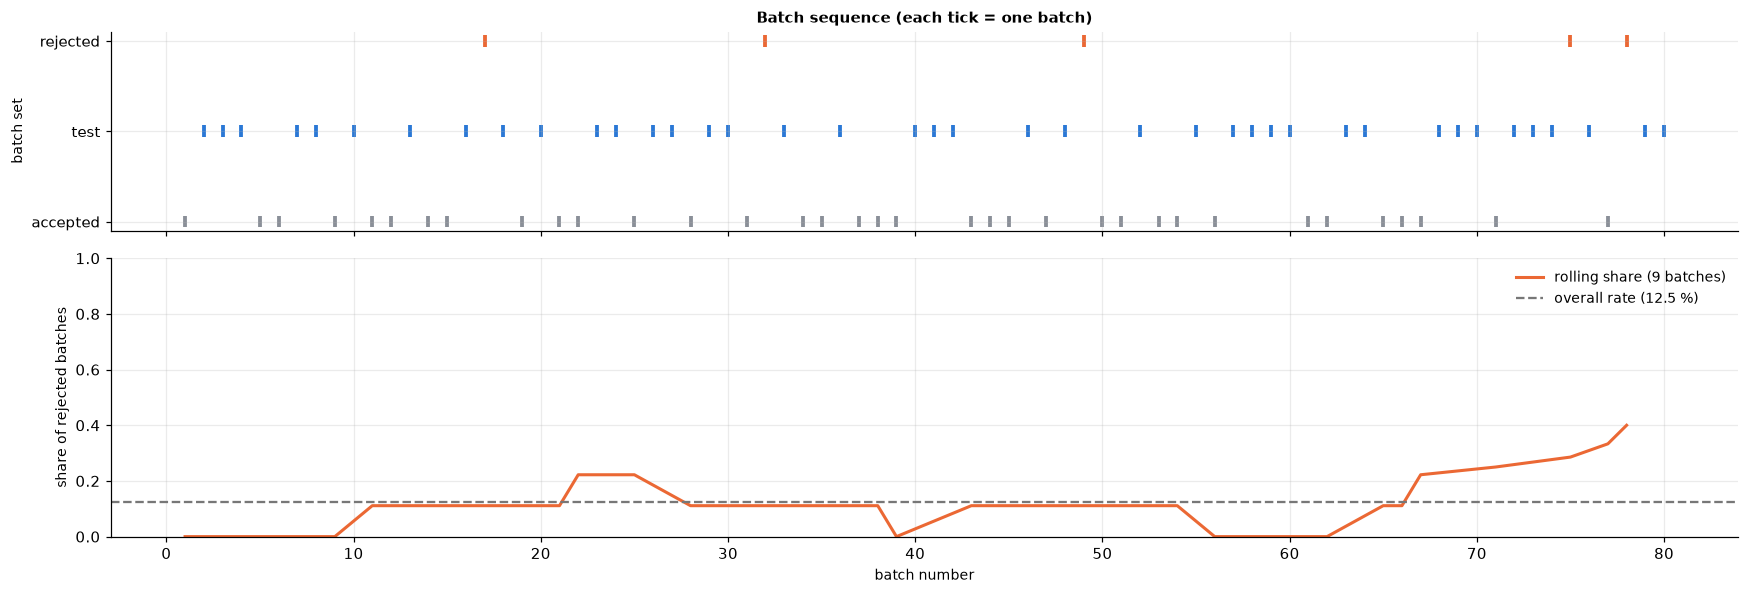

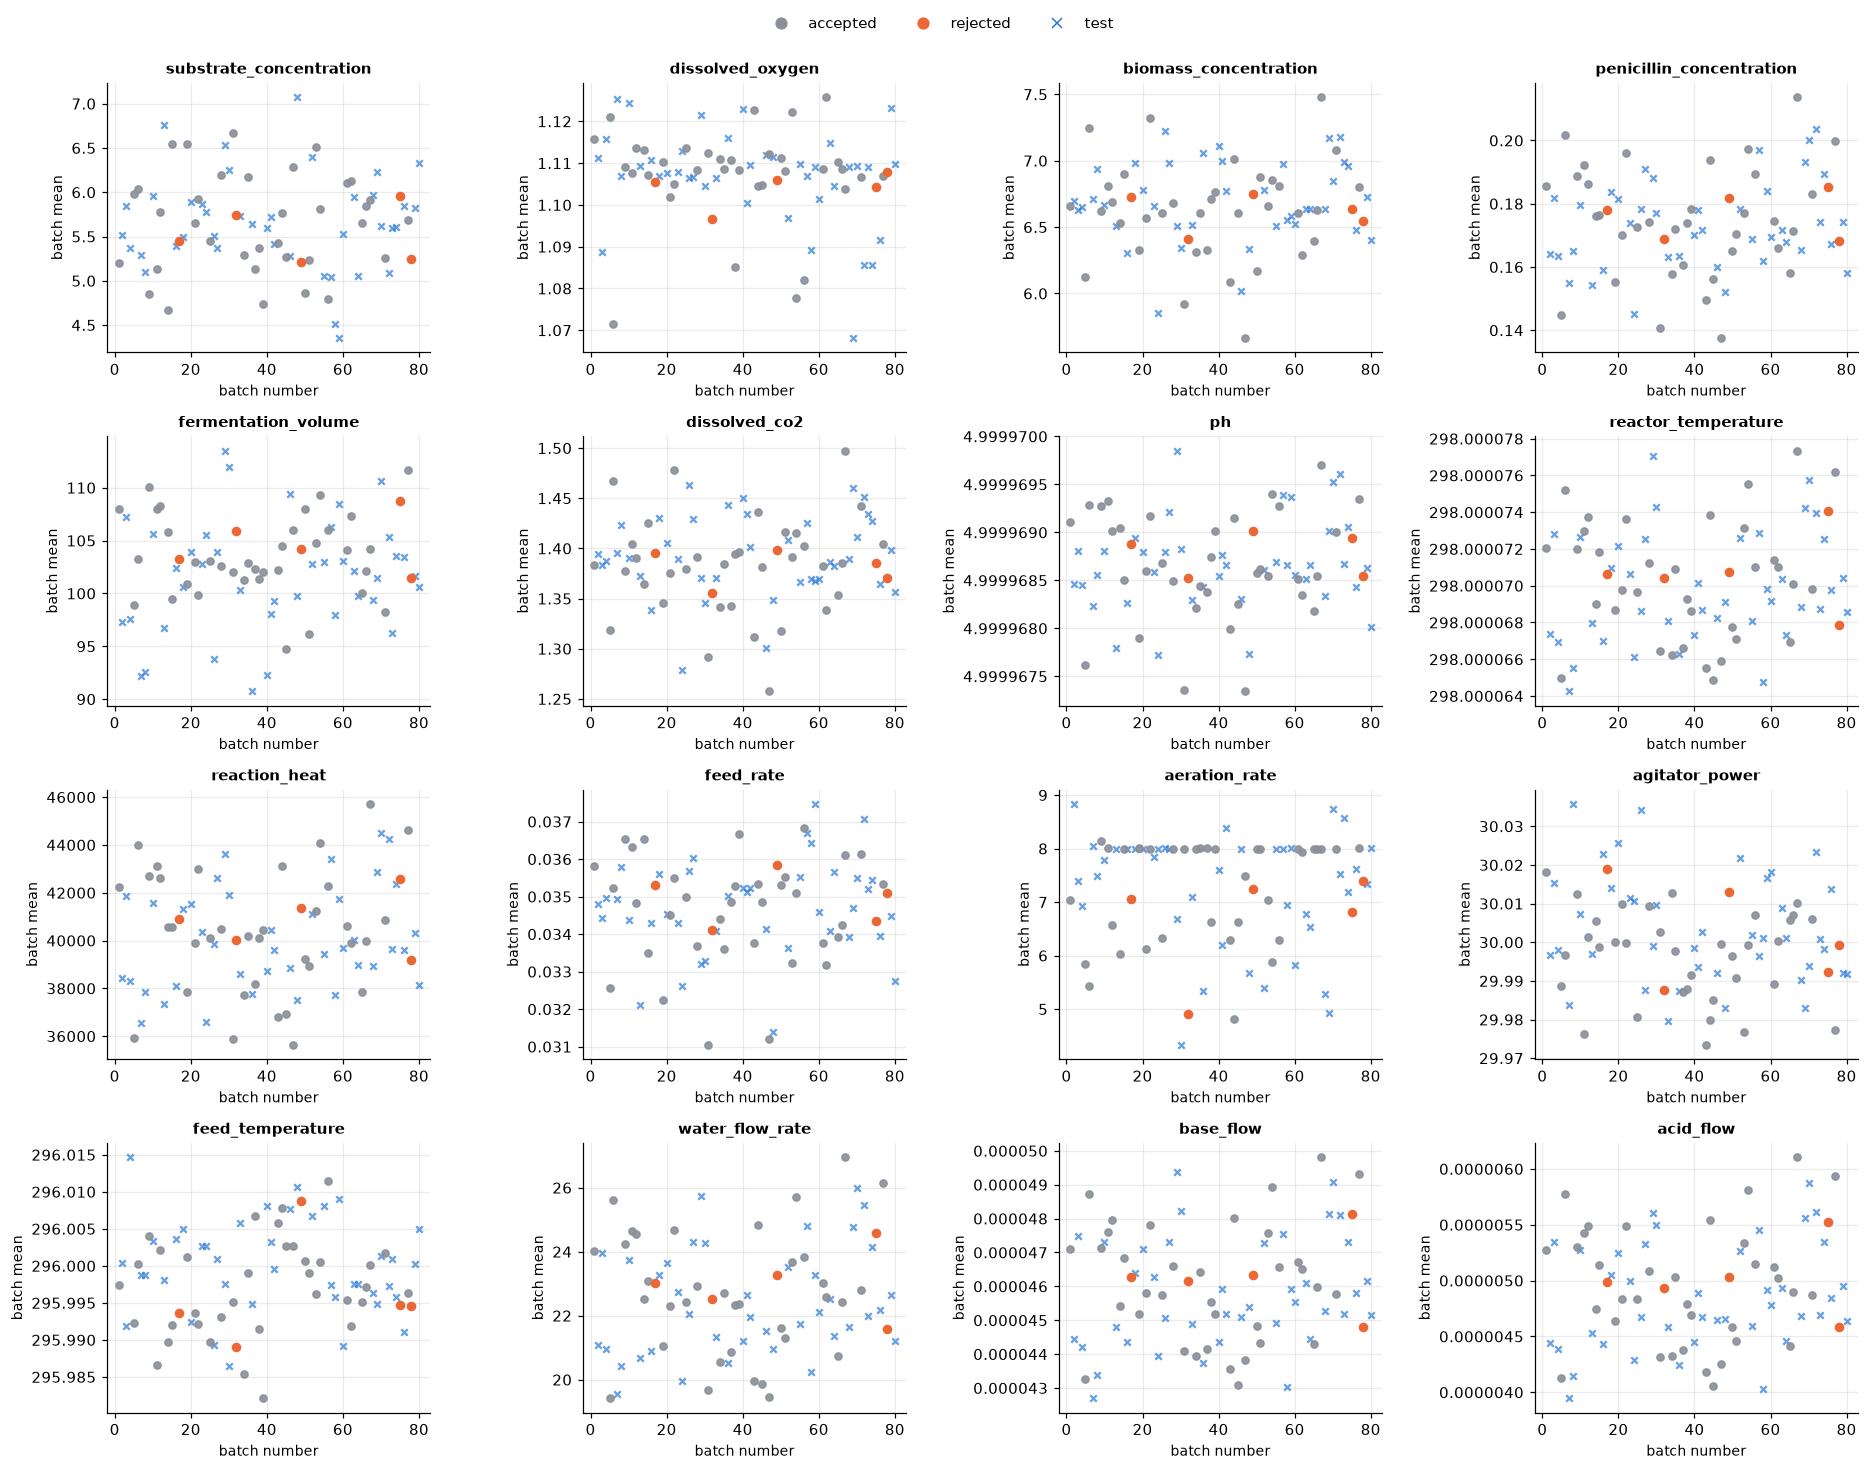

In [7]:
bn=bnum(ids); o=np.argsort(bn); tb=bnum(idt)
fig,ax=plt.subplots(2,1,figsize=(16,5.5),sharex=True,gridspec_kw=dict(height_ratios=[1,1.4]))
ax[0].scatter(bn,np.where(rej,1,0),c=np.where(rej,REJ,ACC),s=60,marker="|",linewidths=2.5)
ax[0].scatter(tb,np.full(len(tb),.5),c=TEST,s=60,marker="|",linewidths=2.5)
ax[0].set_yticks([0,.5,1],["accepted","test","rejected"]); ax[0].set_ylabel("batch set"); ax[0].set_title("Batch sequence (each tick = one batch)")
w=9; rr=pd.Series(rej[o].astype(float)).rolling(w,center=True,min_periods=3).mean()
ax[1].plot(bn[o],rr,color=REJ,lw=2,label=f"rolling share ({w} batches)"); ax[1].axhline(rej.mean(),color="#777",ls="--",label=f"overall rate ({100*rej.mean():.1f} %)")
ax[1].set(ylabel="share of rejected batches",xlabel="batch number",ylim=(0,1)); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(4,4,figsize=(17,13)); off=False
for ax,v in zip(axs.ravel(),V):
    lo,hi,_=bulk_lims(pd.concat([mean[v],meanT[v]])); xl=(-2,83)
    off|=scatter_clip(ax,tb,meanT.loc[idt,v],xl,(lo,hi),TEST,s=18,marker="x",alpha=.7)[2]
    off|=scatter_clip(ax,bn[acc],mean[v][acc],xl,(lo,hi),ACC,s=22,alpha=.9)[2]; off|=scatter_clip(ax,bn[rej],mean[v][rej],xl,(lo,hi),REJ,s=28)[2]
    ax.set_xlim(*xl); ax.set_ylim(lo,hi); ax.set(title=v,xlabel="batch number",ylabel="batch mean")
plt.tight_layout(); top_legend(fig,CLASS_LEG+[dot(TEST,"test","x")]+[OFF_LEG]*off); plt.show()

## 7. `aeration_rate` up close – the variable that gives the rejected batches away
In accepted batches the aeration rate is flat for the whole run (it varies only by ~0.03). In rejected batches it **drops and recovers** during the run, so the within-batch range (max − min) is 1.5–2.3.
- **Left:** trajectories (grey = accepted, one style per rejected batch).
- **Middle:** the range of every calibration batch (one dot per batch). All accepted batches sit at the bottom (at most 0.031), all rejected at the top (at least 1.56). The dashed line is a **threshold** of 0.79, halfway between the two groups: **above the line → rejected, below → accepted**. This simple rule classifies all 40 calibration batches correctly.
- **Right:** the same rule applied to the test batches (same y-axis): orange = above the line, so they look like rejected batches.

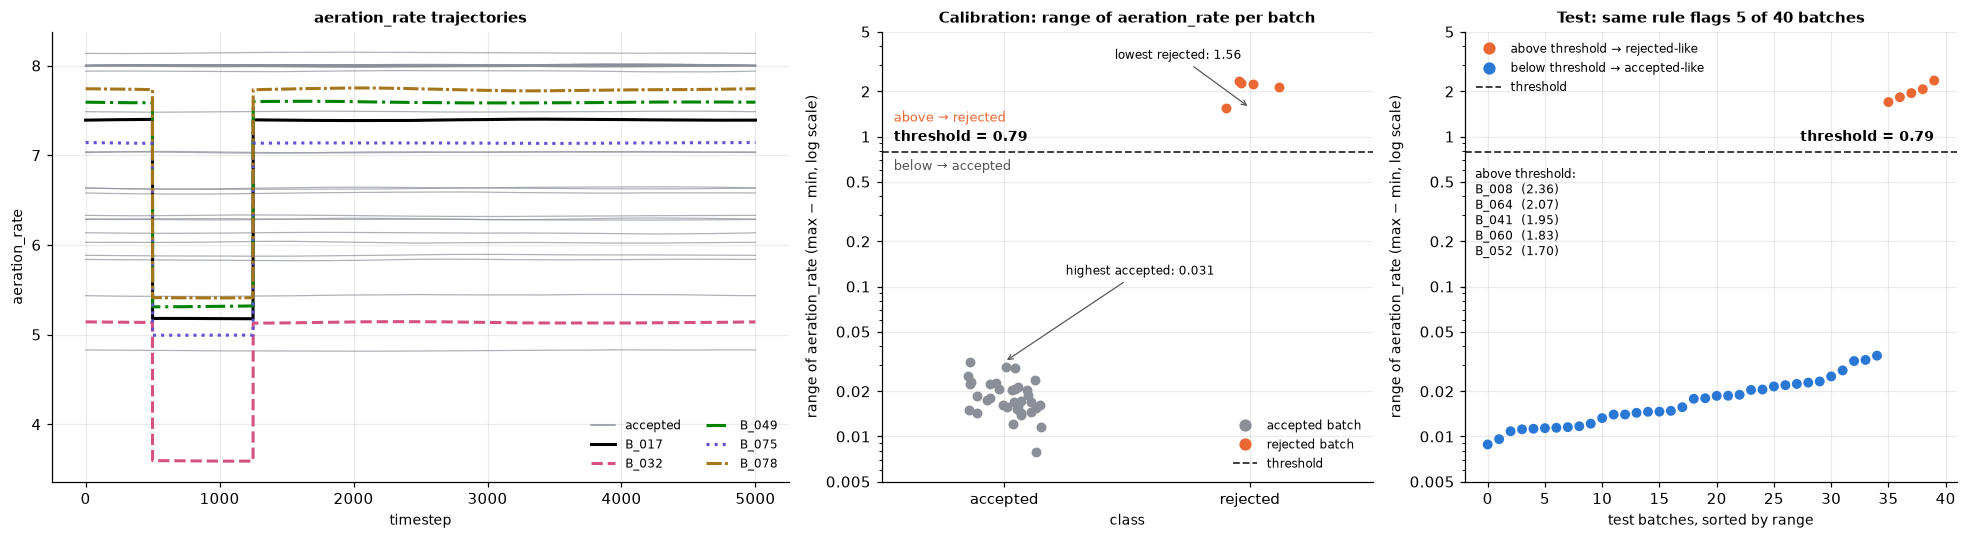

When does the drop happen? (rejected batches)
  B_017: drops from 7.39 to 5.18 between t=500 and t=1250
  B_032: drops from 5.14 to 3.59 between t=500 and t=1250
  B_049: drops from 7.59 to 5.31 between t=500 and t=1250
  B_075: drops from 7.14 to 4.99 between t=500 and t=1250
  B_078: drops from 7.74 to 5.41 between t=500 and t=1250


In [8]:
fig,ax=plt.subplots(1,3,figsize=(18,5),gridspec_kw=dict(width_ratios=[1.5,1,1]))
for b in ACCB: ax[0].plot(t,W["aeration_rate"].loc[b],color=ACC,lw=.8,alpha=.7)
for b in REJB: ax[0].plot(t,W["aeration_rate"].loc[b],color=RS[b]["color"],ls=RS[b]["ls"],lw=2)
ax[0].set(title="aeration_rate trajectories",xlabel="timestep",ylabel="aeration_rate"); ax[0].legend(handles=[line(ACC,"accepted",lw=1)]+REJ_LEG,ncol=2,fontsize=8)
r=rng["aeration_rate"]; thr=(r[acc].max()+r[rej].min())/2
YL=(.005,5)   # same y-axis for calibration and test, so the two panels can be compared directly
# middle: one dot per calibration batch, no box
jit=np.random.default_rng(0).uniform(-.15,.15,len(r))
for k,x0 in (("accepted",0),("rejected",1)):
    m=yc==k; ax[1].scatter(x0+jit[m],r[m],color=PAL[k],s=30,zorder=3)
ax[1].axhline(thr,color=INK,ls="--",lw=1.2)
ax[1].text(-.45,thr*1.12,f"threshold = {thr:.2f}",ha="left",va="bottom",fontsize=9,fontweight="bold")
ax[1].text(-.45,thr*1.12*1.35,"above → rejected",ha="left",va="bottom",fontsize=8.5,color=REJ)
ax[1].text(-.45,thr/1.12,"below → accepted",ha="left",va="top",fontsize=8.5,color="#555")
ax[1].annotate(f"highest accepted: {r[acc].max():.3f}",xy=(0,r[acc].max()),xytext=(.25,.12),textcoords=("data","data"),fontsize=8,arrowprops=dict(arrowstyle="->",color="#555",lw=.8))
ax[1].annotate(f"lowest rejected: {r[rej].min():.2f}",xy=(1,r[rej].min()),xytext=(.45,3.3),fontsize=8,arrowprops=dict(arrowstyle="->",color="#555",lw=.8))
ax[1].set_yscale("log"); plain_log(ax[1]); ax[1].set_ylim(*YL); ax[1].set_xlim(-.5,1.5); ax[1].set_xticks([0,1],["accepted","rejected"])
ax[1].set(title="Calibration: range of aeration_rate per batch",xlabel="class",ylabel="range of aeration_rate (max − min, log scale)")
ax[1].legend(handles=[dot(ACC,"accepted batch"),dot(REJ,"rejected batch"),line(INK,"threshold",lw=1.2,ls="--")],loc="lower right",fontsize=8)
# right: same rule applied to the test batches
rt=rngT["aeration_rate"].sort_values(); above=rt>thr
ax[2].scatter(np.arange(len(rt)),rt.values,c=np.where(above,REJ,TEST),s=30,zorder=3); ax[2].axhline(thr,color=INK,ls="--",lw=1.2)
ax[2].text(len(rt)-1,thr*1.12,f"threshold = {thr:.2f}",ha="right",va="bottom",fontsize=9,fontweight="bold")
ax[2].set_yscale("log"); plain_log(ax[2]); ax[2].set_ylim(*YL)
ax[2].set(title=f"Test: same rule flags {int(above.sum())} of {len(rt)} batches",xlabel="test batches, sorted by range",ylabel="range of aeration_rate (max − min, log scale)")
ax[2].legend(handles=[dot(REJ,"above threshold → rejected-like"),dot(TEST,"below threshold → accepted-like"),line(INK,"threshold",lw=1.2,ls="--")],loc="upper left",fontsize=8)
ax[2].text(.02,.7,"above threshold:\n"+"\n".join(f"{b}  ({rt[b]:.2f})" for b in rt.index[above][::-1]),transform=ax[2].transAxes,fontsize=8,va="top")
plt.tight_layout(); plt.show()
print("When does the drop happen? (rejected batches)")
for b in REJB:
    s=W["aeration_rate"].loc[b]; lo=s[s<s.iloc[0]-.5]
    print(f"  {b}: {'no drop > 0.5' if lo.empty else f'drops from {s.iloc[0]:.2f} to {lo.min():.2f} between t={lo.index.min()} and t={lo.index.max()}'}")

## 8. Batches in feature space (PCA)
Each batch is summarised by the mean, std, range and final value of every variable, robust-scaled, then projected to 2D. If the classes formed separate clouds, a simple model would have something easy to learn.

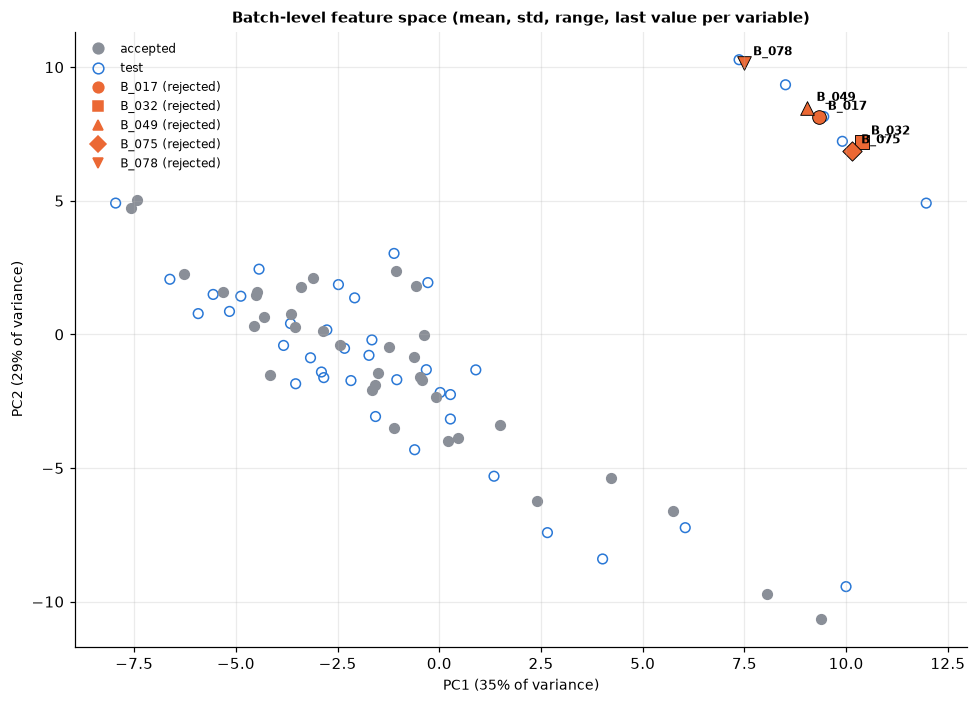

Top loadings


,PC1,PC2
aeration_rate_std,0.50,0.49
aeration_rate_range,0.50,0.49
dissolved_oxygen_last,-0.49,0.44
dissolved_oxygen_mean,-0.24,0.21
dissolved_oxygen_range,0.15,-0.15
dissolved_oxygen_std,0.13,-0.16


In [9]:
def feats(Wd):
    return pd.concat([pd.DataFrame({v:Wd[v].mean(axis=1) for v in V}).add_suffix("_mean"),pd.DataFrame({v:Wd[v].std(axis=1) for v in V}).add_suffix("_std"),
                      pd.DataFrame({v:Wd[v].max(axis=1)-Wd[v].min(axis=1) for v in V}).add_suffix("_range"),pd.DataFrame({v:Wd[v].iloc[:,-1] for v in V}).add_suffix("_last")],axis=1)
Fc=feats(W); Ft=feats(WT); keep=Fc.columns[Fc.std()>0]; Fc,Ft=Fc[keep],Ft[keep]
sc=RobustScaler().fit(Fc); Zc=np.clip(sc.transform(Fc),-10,10); Zt=np.clip(sc.transform(Ft),-10,10); pca=PCA(2).fit(Zc); Pc,Pt=pca.transform(Zc),pca.transform(Zt)
fig,ax=plt.subplots(figsize=(9,6.5))
ax.scatter(Pt[:,0],Pt[:,1],facecolors="none",edgecolors=TEST,s=40); ax.scatter(Pc[acc,0],Pc[acc,1],c=ACC,s=40)
for b in REJB:
    k=ids.index(b); ax.scatter(*Pc[k],color=REJ,marker=RS[b]["marker"],s=80,edgecolors="k",lw=.6); ax.annotate(b,Pc[k],xytext=(6,5),textcoords="offset points",fontweight="bold",fontsize=8)
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}% of variance)"); ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}% of variance)")
ax.set_title("Batch-level feature space (mean, std, range, last value per variable)")
ax.legend(handles=[dot(ACC,"accepted"),hollow(TEST,"test")]+[dot(REJ,f"{b} (rejected)",RS[b]["marker"]) for b in REJB],loc="best",fontsize=8)
plt.tight_layout(); plt.show()
load_=pd.DataFrame(pca.components_.T,index=Fc.columns,columns=["PC1","PC2"]); print("Top loadings"); display(load_.reindex(load_.PC1.abs().sort_values(ascending=False).index).head(6).round(2))

## 9. Which summary features separate the classes best?
Every batch is summarised by 4 numbers per variable: **`_mean`** (average over the run), **`_std`** (standard deviation), **`_range`** (max − min) and **`_last`** (value at the end). Each of these features is then scored on its own with the AUC: 0.5 = no information, 1 = it separates accepted and rejected perfectly. With only 5 rejected batches, treat anything below ~0.9 with caution.
- **Left:** the 15 best features, with their AUC. Violet = a feature of `aeration_rate`, dark grey = a feature of another variable.
- **Right:** the two best features are `aeration_rate_std` and `aeration_rate_range` (both AUC = 1.00). They measure the same thing (how much the aeration rate moves), so plotting them against each other adds nothing. Instead the plot shows the best `aeration_rate` feature against **the best feature of any other variable**. The dashed line is the threshold that separates the classes.
- **Bottom:** within-batch range of the 8 variables whose range separates best.

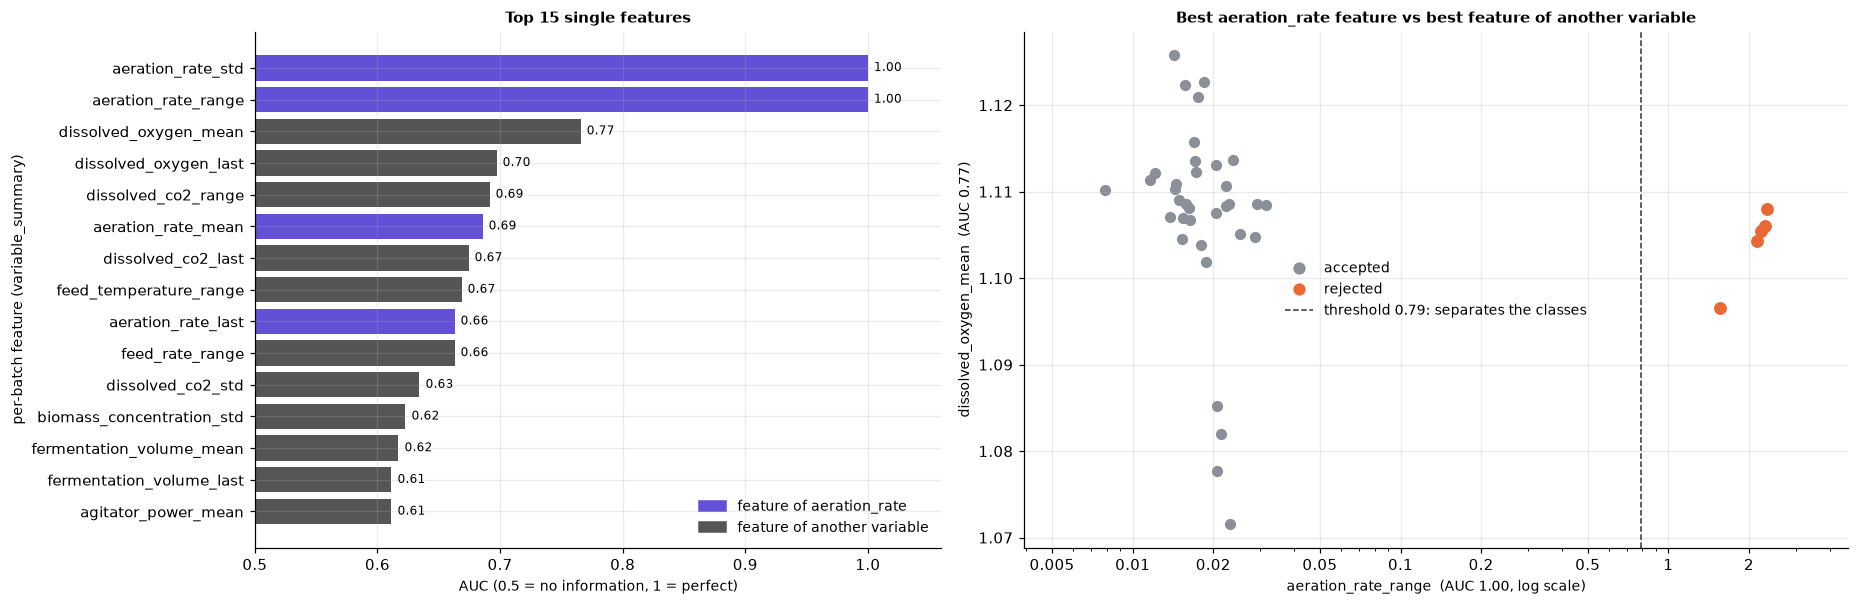

x-axis aeration_rate_range: accepted max 0.031 | rejected min 1.556
y-axis dissolved_oxygen_mean: accepted 1.0716–1.1258 | rejected 1.0965–1.1080  -> overlaps, no clean separation


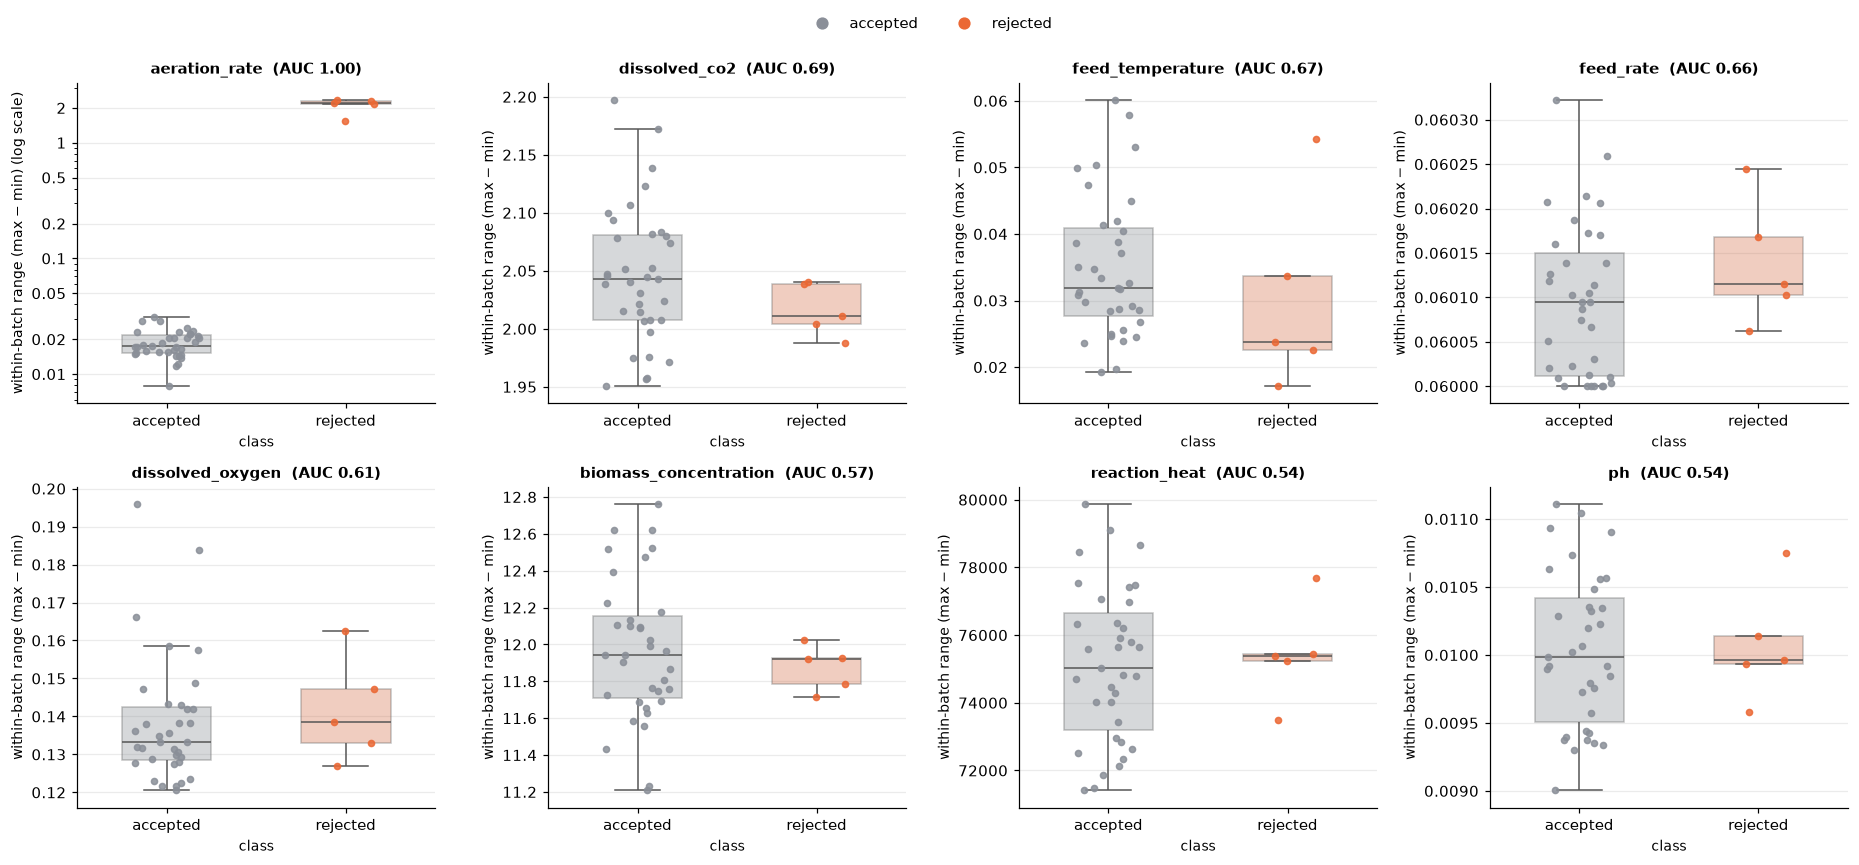

In [10]:
auc=pd.Series({c:roc_auc_score(rej,Fc[c]) for c in Fc.columns}); auc=(auc-.5).abs()+.5
top=auc.sort_values(ascending=False).head(15)
HI="#6250d6"   # violet highlight for aeration_rate features (orange is reserved for 'rejected')
fig,ax=plt.subplots(1,2,figsize=(17,5.6),gridspec_kw=dict(width_ratios=[1,1.2]))
ax[0].barh(top.index[::-1],top.values[::-1],color=[HI if c.startswith("aeration_rate") else "#555" for c in top.index[::-1]])
for yy,(c,v) in enumerate(top[::-1].items()): ax[0].text(v+.005,yy,f"{v:.2f}",va="center",fontsize=8)
ax[0].set_xlim(.5,1.06); ax[0].set(title="Top 15 single features",xlabel="AUC (0.5 = no information, 1 = perfect)",ylabel="per-batch feature (variable_summary)")
ax[0].legend(handles=[patch(HI,"feature of aeration_rate",a=1),patch("#555","feature of another variable",a=1)],loc="lower right")
fx="aeration_rate_range"; fy=auc[[c for c in auc.index if not c.startswith("aeration_rate")]].idxmax()
ax[1].scatter(Fc.loc[acc,fx],Fc.loc[acc,fy],c=ACC,s=40); ax[1].scatter(Fc.loc[rej,fx],Fc.loc[rej,fy],c=REJ,s=55)
thr_=(Fc.loc[acc,fx].max()+Fc.loc[rej,fx].min())/2; ax[1].axvline(thr_,color=INK,ls="--",lw=1)
ax[1].set_xscale("log"); plain_log(ax[1],"x"); ax[1].set_xlim(Fc[fx].min()/2,Fc[fx].max()*2)
ax[1].set(xlabel=f"{fx}  (AUC {auc[fx]:.2f}, log scale)",ylabel=f"{fy}  (AUC {auc[fy]:.2f})",title="Best aeration_rate feature vs best feature of another variable")
ax[1].legend(handles=CLASS_LEG+[line(INK,f"threshold {thr_:.2f}: separates the classes",lw=1,ls="--")],loc="center")
plt.tight_layout(); plt.show()
print(f"x-axis {fx}: accepted max {Fc.loc[acc,fx].max():.3f} | rejected min {Fc.loc[rej,fx].min():.3f}")
print(f"y-axis {fy}: accepted {Fc.loc[acc,fy].min():.4f}–{Fc.loc[acc,fy].max():.4f} | rejected {Fc.loc[rej,fy].min():.4f}–{Fc.loc[rej,fy].max():.4f}  -> overlaps, no clean separation")
auc_r=pd.Series({v:auc[v+"_range"] for v in V if v+"_range" in auc}).sort_values(ascending=False)
fig,axs=plt.subplots(2,4,figsize=(17,7.5))
for ax,v in zip(axs.ravel(),auc_r.index[:8]):
    class_box(ax,rng[v].values,yc,"within-batch range (max − min)"); ax.set_title(f"{v}  (AUC {auc_r[v]:.2f})")
top_legend(fig,CLASS_LEG); plt.tight_layout(); plt.show()

## 10. Relationships between variables
Spearman correlation between variables (blue = negative, red = positive). **Left:** over all timesteps (moment-to-moment co-movement, mostly the shared recipe). **Right:** over batch means (do batches with a high level in one variable also have a high level in another?).

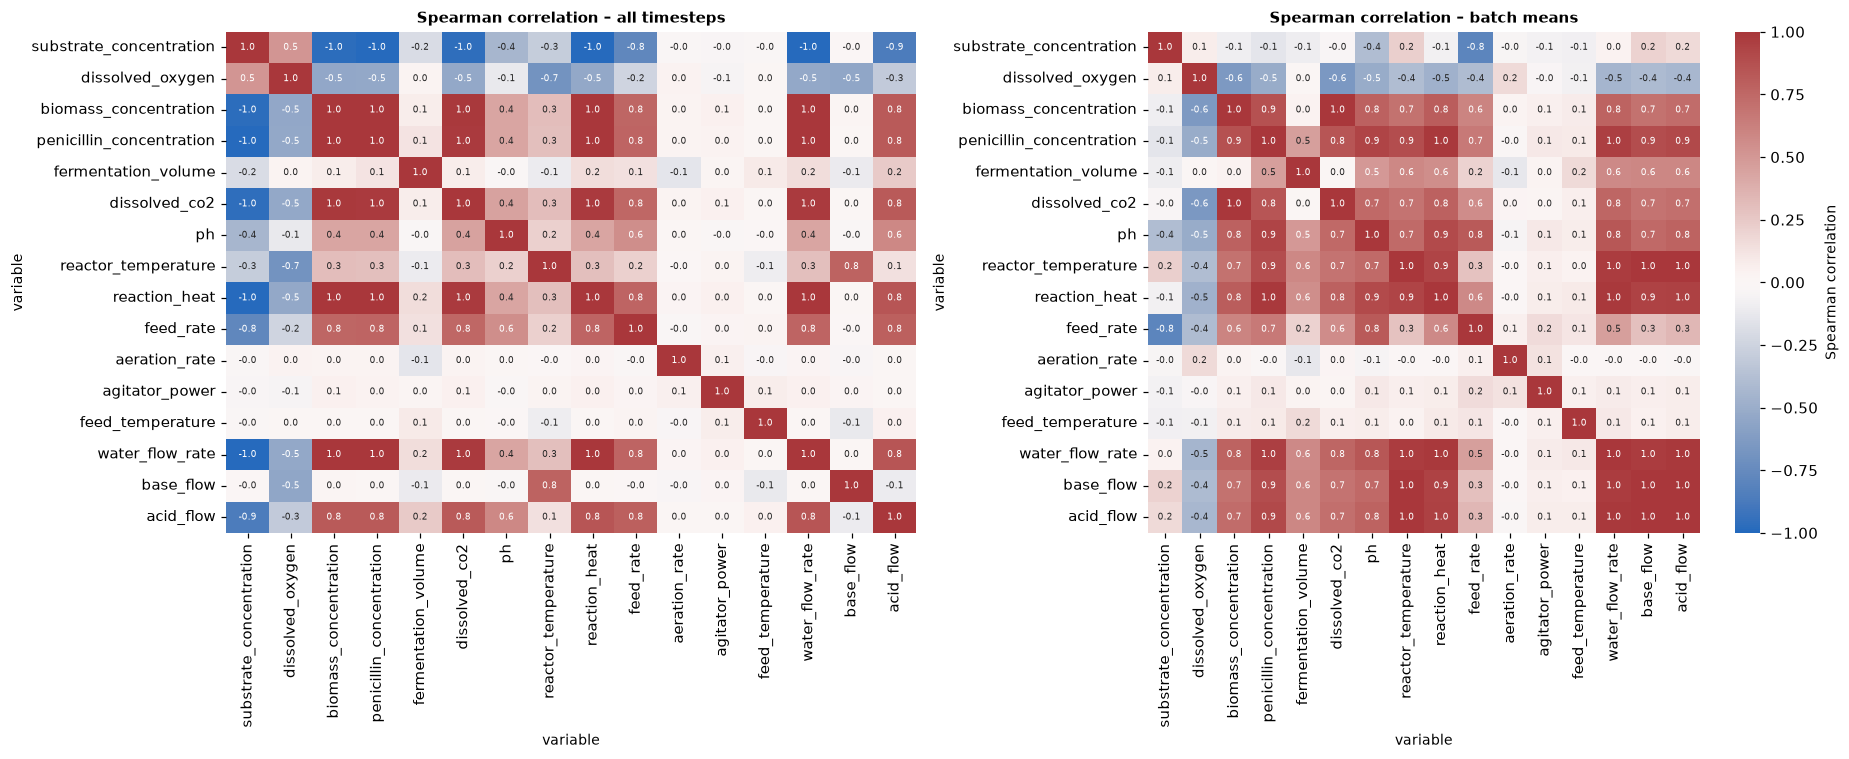

In [11]:
fig,ax=plt.subplots(1,2,figsize=(17,7))
sns.heatmap(cal[V].sample(50000,random_state=0).corr("spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,ax=ax[0],annot=True,fmt=".1f",annot_kws=dict(size=6),cbar=False); ax[0].set_title("Spearman correlation – all timesteps")
sns.heatmap(mean.corr("spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,ax=ax[1],annot=True,fmt=".1f",annot_kws=dict(size=6),cbar_kws=dict(label="Spearman correlation")); ax[1].set_title("Spearman correlation – batch means")
for a in ax: a.set(xlabel="variable",ylabel="variable"); a.grid(False)
plt.tight_layout(); plt.show()

## 11. Calibration vs test: same distribution?
If test batches looked very different from calibration, a rule learnt on calibration could fail.
- **Top:** batch means on a common scale (robust z-score: minus the calibration median, divided by the calibration IQR).
- **Bottom:** four key quantities – feed-start time, final penicillin, initial volume, initial substrate. For each value range, grey bar = calibration batches, blue bar = test batches.

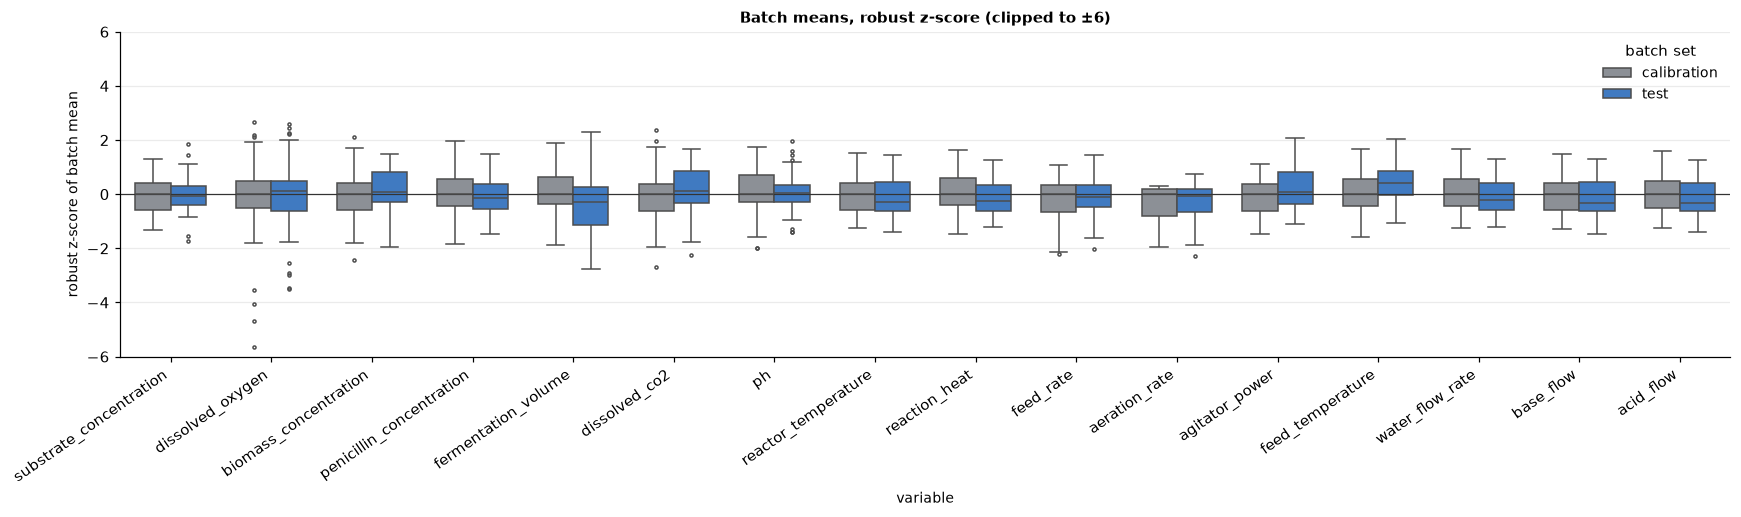

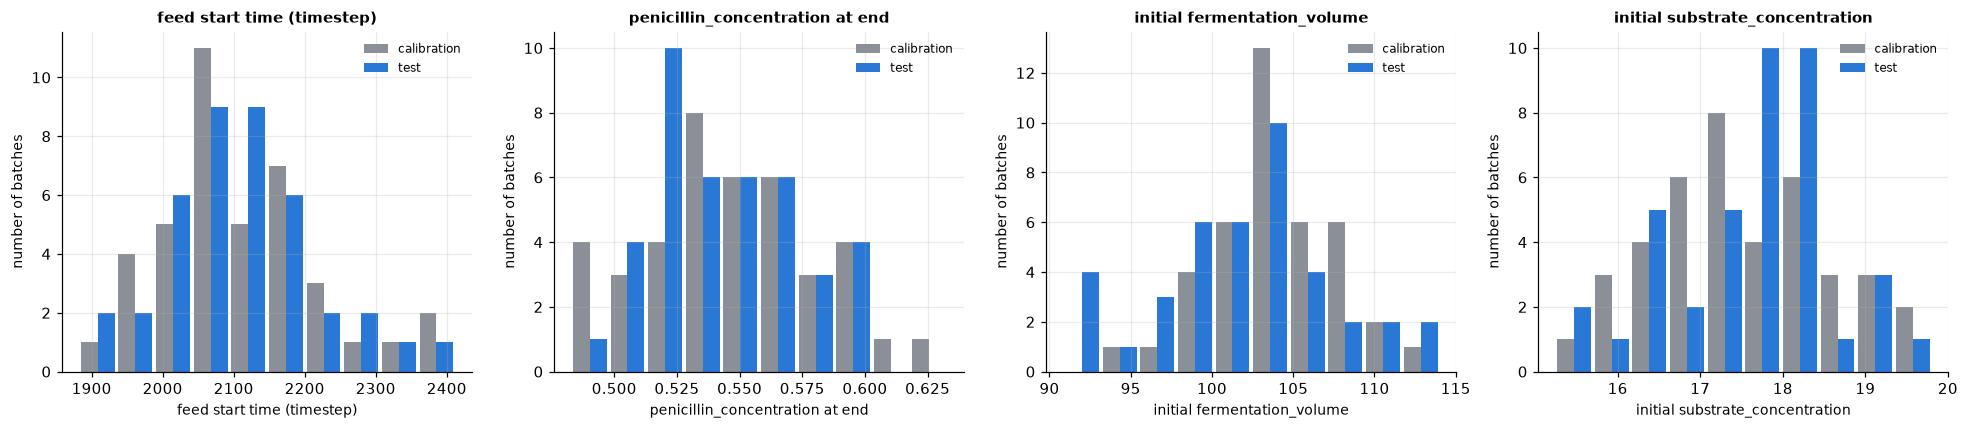

In [12]:
ctr=mean.median(); iqr=(mean.quantile(.75)-mean.quantile(.25)).replace(0,np.nan); zc=(mean-ctr)/iqr; zt=(meanT-ctr)/iqr
d=pd.concat([zc.assign(set="calibration"),zt.assign(set="test")]).melt(id_vars="set",var_name="variable",value_name="z").dropna()
fig,ax=plt.subplots(figsize=(16,4.8)); sns.boxplot(data=d,x="variable",y="z",hue="set",palette={"calibration":ACC,"test":TEST},ax=ax,fliersize=2,width=.7)
ax.set_ylim(-6,6); ax.axhline(0,color=INK,lw=.8); ax.set(title="Batch means, robust z-score (clipped to ±6)",xlabel="variable",ylabel="robust z-score of batch mean")
ax.legend(title="batch set",loc="upper right"); plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(1,4,figsize=(18,4))
for ax,(a,b,name) in zip(axs,[(fs,fst,"feed start time (timestep)"),(end["penicillin_concentration"],endT["penicillin_concentration"],"penicillin_concentration at end"),
                              (W["fermentation_volume"].iloc[:,0],WT["fermentation_volume"].iloc[:,0],"initial fermentation_volume"),(W["substrate_concentration"].iloc[:,0],WT["substrate_concentration"].iloc[:,0],"initial substrate_concentration")]):
    bins=np.histogram_bin_edges(np.r_[a.values,b.values],10)
    ax.hist([a,b],bins=bins,color=[ACC,TEST],label=["calibration","test"],rwidth=.9)
    ax.set(title=name,xlabel=name,ylabel="number of batches"); ax.legend(loc="upper right",fontsize=8)
plt.tight_layout(); plt.show()

### 11.1 Initial values (t = 0)
Does every test batch *start* inside the range covered by the calibration batches? The calibration range is the min–max of each variable's t = 0 value over the 40 calibration batches. Variables identical in every batch at t = 0 cannot be out of range and are listed as constant.

In [13]:
c0=cal.groupby("batch_id").first()[ALL]; t0=test.groupby("batch_id").first()[ALL]
S=pd.DataFrame({"cal_min":c0.min(),"cal_max":c0.max(),"cal_std":c0.std(),"test_min":t0.min(),"test_max":t0.max()})
S["test_out_of_range"]=[int(((t0[v]<c0[v].min())|(t0[v]>c0[v].max())).sum()) for v in ALL]
const0=[v for v in ALL if c0[v].nunique()==1 and t0[v].nunique()==1 and c0[v].iloc[0]==t0[v].iloc[0]]
print("identical in every batch at t=0 (calibration and test):",const0)
display(S.drop(index=const0).style.format({k:"{:.5g}" for k in ["cal_min","cal_max","cal_std","test_min","test_max"]}).background_gradient(subset=["test_out_of_range"],cmap="Oranges"))
rows=[]
for v in S.index.difference(const0):
    lo,hi,s_=c0[v].min(),c0[v].max(),c0[v].std()
    for b,x in t0[v].items():
        if x<lo or x>hi:
            ex=lo-x if x<lo else x-hi; rows.append(dict(batch=b,variable=v,test_value=x,side="below" if x<lo else "above",cal_min=lo,cal_max=hi,excess=ex,excess_pct_of_cal_range=100*ex/(hi-lo),excess_in_cal_std=ex/s_))
OUT=pd.DataFrame(rows).sort_values(["batch","excess_pct_of_cal_range"],ascending=[True,False]).reset_index(drop=True)
print(f"{len(OUT)} out-of-range values in {OUT.batch.nunique()} of {len(t0)} test batches")
display(OUT.style.format({"test_value":"{:.5g}","cal_min":"{:.5g}","cal_max":"{:.5g}","excess":"{:.4g}","excess_pct_of_cal_range":"{:.1f}","excess_in_cal_std":"{:.2f}"}).background_gradient(subset=["excess_pct_of_cal_range"],cmap="Oranges"))

identical in every batch at t=0 (calibration and test): ['penicillin_concentration', 'ph', 'reactor_temperature', 'reaction_heat', 'feed_rate', 'agitator_power', 'feed_temperature', 'water_flow_rate', 'hot_cold_switch', 'base_flow', 'acid_flow', 'feed_substate_concentration', 'cooling_water_temperature', 'heating_water_temperature']


,cal_min,cal_max,cal_std,test_min,test_max,test_out_of_range
substrate_concentration,15.589,19.803,1.0584,15.243,19.519,2
dissolved_oxygen,1.156,1.164,0.0020112,1.1567,1.1655,2
biomass_concentration,0.065669,0.18069,0.0282,0.07677,0.19347,1
fermentation_volume,94.864,112,3.7837,90.838,114,7
dissolved_co2,0.30998,0.56113,0.060014,0.36703,0.63083,3
aeration_rate,4.8289,8.1353,0.96126,4.3289,8.8353,5


20 out-of-range values in 18 of 40 test batches


,batch,variable,test_value,side,cal_min,cal_max,excess,excess_pct_of_cal_range,excess_in_cal_std
0,B_002,dissolved_co2,0.63083,above,0.30998,0.56113,0.0697,27.8,1.16
1,B_002,aeration_rate,8.8353,above,4.8289,8.1353,0.7,21.2,0.73
2,B_007,fermentation_volume,92.294,below,94.864,112,2.57,15.0,0.68
3,B_008,fermentation_volume,92.694,below,94.864,112,2.171,12.7,0.57
4,B_026,fermentation_volume,93.879,below,94.864,112,0.9854,5.8,0.26
5,B_029,fermentation_volume,114,above,94.864,112,2.001,11.7,0.53
6,B_030,aeration_rate,4.3289,below,4.8289,8.1353,0.5,15.1,0.52
7,B_030,fermentation_volume,112.42,above,94.864,112,0.4144,2.4,0.11
8,B_036,fermentation_volume,90.838,below,94.864,112,4.026,23.5,1.06
9,B_040,fermentation_volume,92.439,below,94.864,112,2.425,14.2,0.64


One panel per variable that varies at t = 0. **Grey band** = calibration min–max; left column = calibration batches (grey accepted, orange rejected), right column = test batches (hollow blue = inside the range, **black diamond = outside it**, with its batch id next to it).

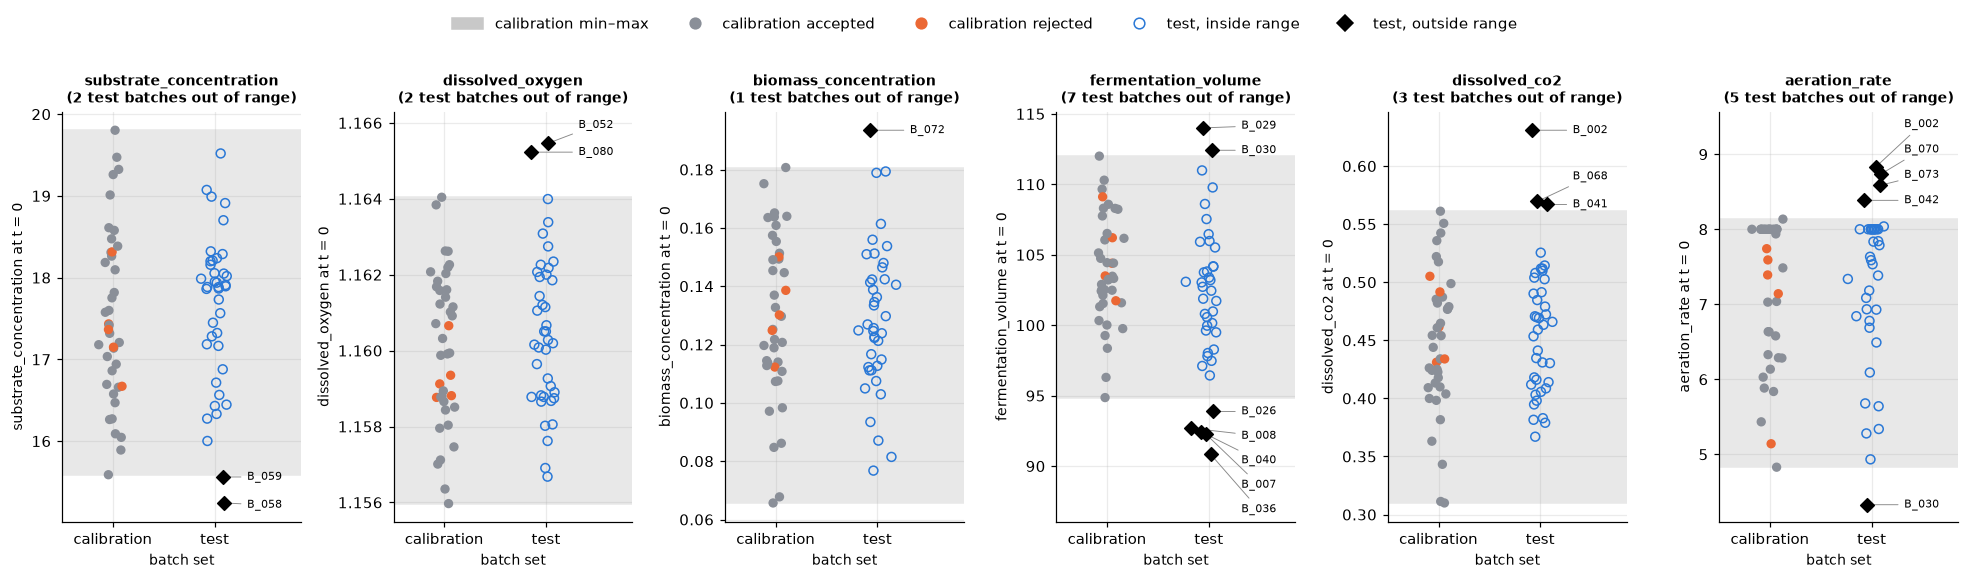

In [14]:
vv=[v for v in ALL if v not in const0]; fig,axs=plt.subplots(1,len(vv),figsize=(3*len(vv),4.8))
rng_=np.random.default_rng(0)
for ax,v in zip(axs,vv):
    lo,hi=c0[v].min(),c0[v].max(); ax.axhspan(lo,hi,color="#e8e8e8",zorder=0)
    ax.scatter(rng_.normal(0,.06,len(c0)),c0[v],c=[REJ if y[b]=="rejected" else ACC for b in c0.index],s=26,zorder=3)
    out=(t0[v]<lo)|(t0[v]>hi); xs=1+rng_.normal(0,.06,len(t0))
    ax.scatter(xs[~out.values],t0[v][~out],facecolors="none",edgecolors=TEST,s=34,zorder=3)
    ax.scatter(xs[out.values],t0[v][out],c="#000000",s=40,zorder=4,marker="D")
    # labels: spread vertically so they never overlap; a thin line points from each label to its diamond
    span=max(np.r_[c0[v].values,t0[v].values])-min(np.r_[c0[v].values,t0[v].values]); gap=.075*span; ylo,yhi=ax.get_ylim()
    pos=dict(zip(t0.index,xs))
    for side,sel in (("above",t0[v]>hi),("below",t0[v]<lo)):
        pts=t0[v][sel].sort_values(ascending=(side=="above")); prev=None
        for b,val in pts.items():
            ty=val if prev is None else (max(val,prev+gap) if side=="above" else min(val,prev-gap)); prev=ty; ylo,yhi=min(ylo,ty-gap/2),max(yhi,ty+gap/2)
            ax.annotate(b,xy=(pos[b],val),xytext=(1.32,ty),fontsize=7.5,va="center",arrowprops=dict(arrowstyle="-",color="#888",lw=.6))
    ax.set_ylim(ylo,yhi)
    ax.set_xticks([0,1],["calibration","test"]); ax.set_xlim(-.5,1.85); ax.set_xlabel("batch set"); ax.set_ylabel(f"{v} at t = 0"); ax.set_title(f"{v}\n({int(out.sum())} test batches out of range)",fontsize=9)
top_legend(fig,[patch("#c8c8c8","calibration min–max",a=1),dot(ACC,"calibration accepted"),dot(REJ,"calibration rejected"),hollow(TEST,"test, inside range"),dot("#000000","test, outside range","D")],y=1.02)
plt.tight_layout(); plt.show()

**Reading it:** 14 of the 20 variables are identical in every batch at t = 0, so only six can be out of range: `substrate_concentration`, `dissolved_oxygen`, `biomass_concentration`, `fermentation_volume`, `dissolved_co2` and `aeration_rate`. `fermentation_volume` (7 test batches) and `aeration_rate` (5) account for most cases. Excesses are mostly small (a few % of the calibration range, below one calibration std); the largest are `B_002` `dissolved_co2` (28 % of the range) and `B_036` `fermentation_volume` (23 %). With only 40 calibration batches, a test batch falling slightly outside the observed min–max is expected for a few variables.

## 12. Rejected batches up close
Three closer looks at what else (besides the aeration drop) might distinguish the 5 rejected batches.

### 12.1 Phase alignment – same recipe, slightly different timing
The feed turns on between t ≈ 1900 and 2400. **Top:** feed-start time per batch. **Bottom:** trajectories re-aligned so that t = 0 is each batch's feed start; if rejected batches differed in timing only, they would line up with the grey ones after alignment.

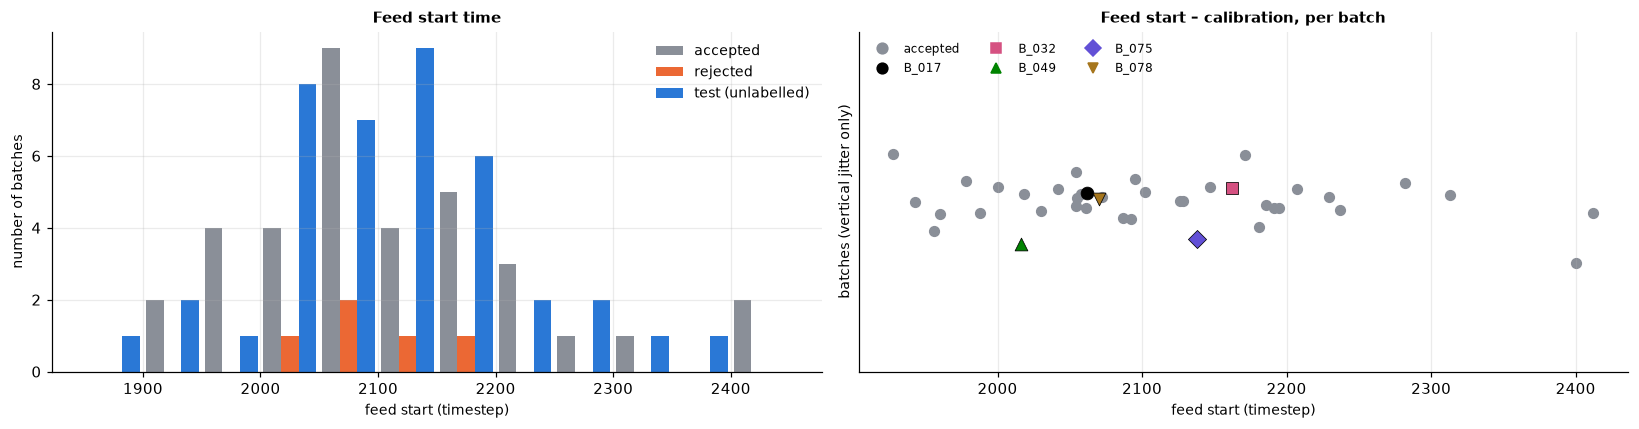

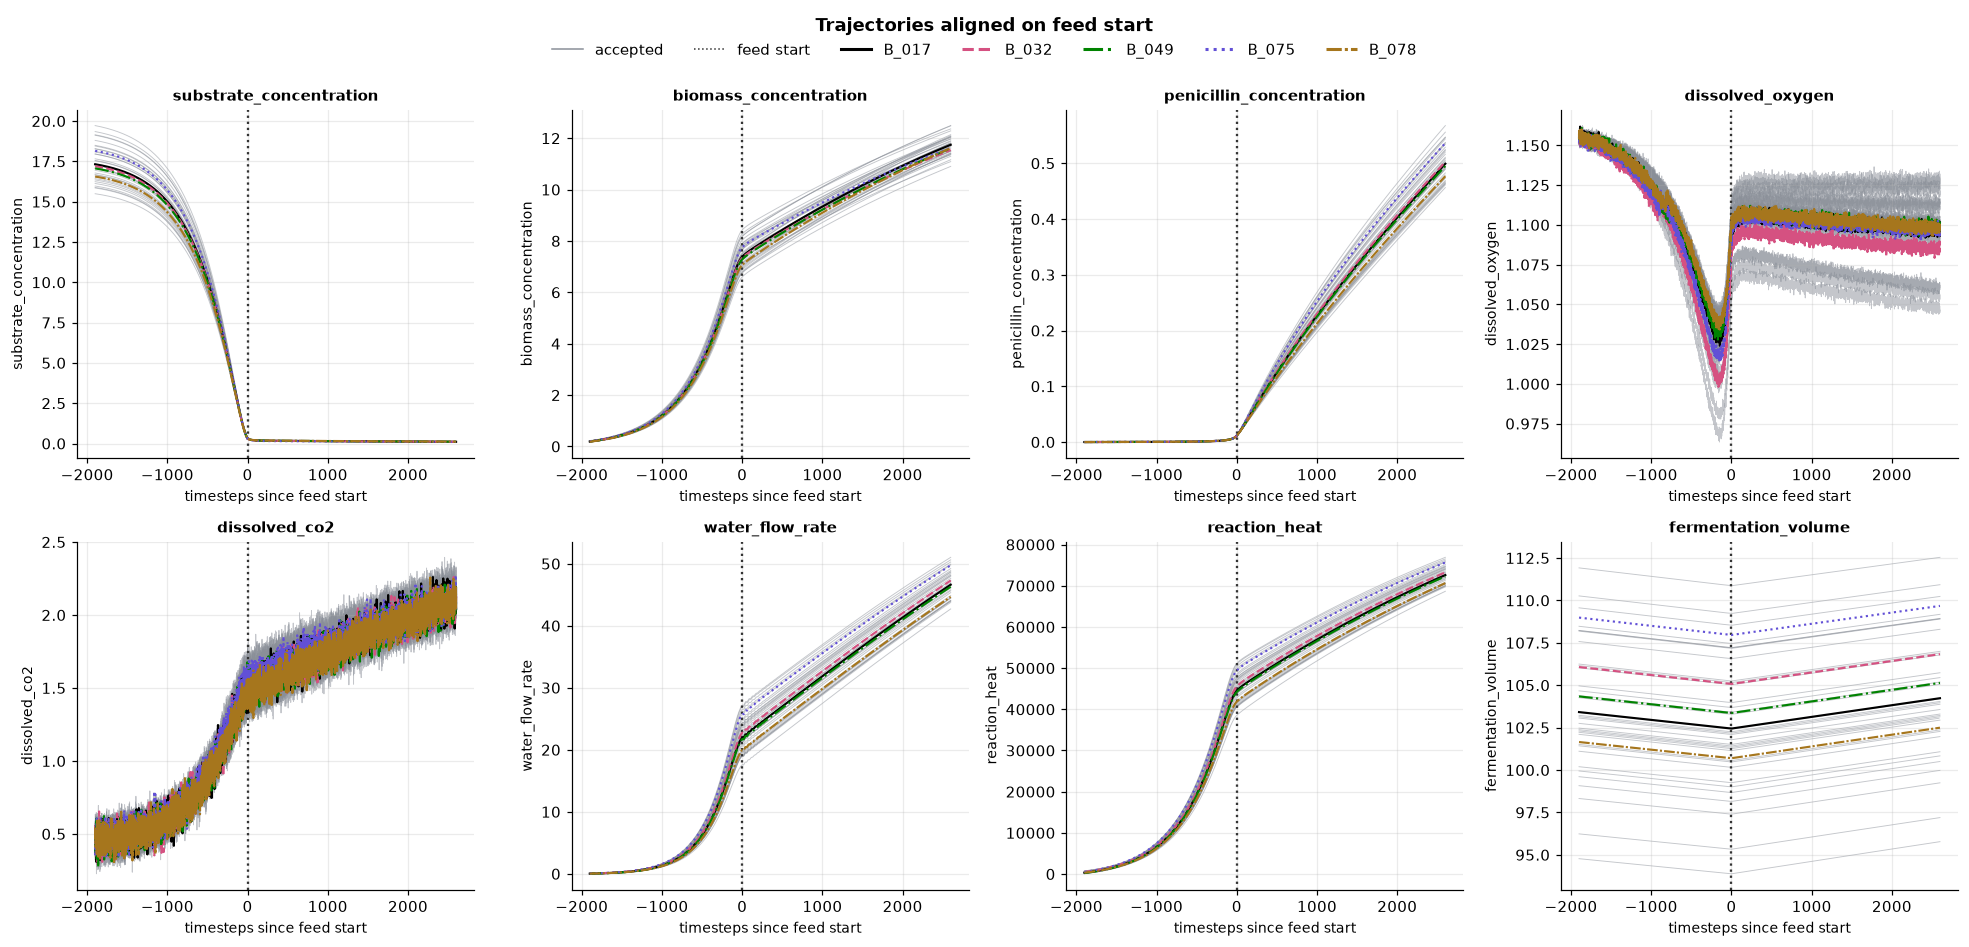

In [15]:
fig,ax=plt.subplots(1,2,figsize=(15,4))
bins=np.arange(1850,2475,50)
ax[0].hist([fs[acc],fs[rej],fst],bins=bins,color=[ACC,REJ,TEST],label=["accepted","rejected","test (unlabelled)"],rwidth=.9)
ax[0].set(title="Feed start time",xlabel="feed start (timestep)",ylabel="number of batches"); ax[0].legend()
jit=np.random.default_rng(1).normal(0,.04,len(ids))
ax[1].scatter(fs[ACCB],1+jit[acc],c=ACC,s=40)
for b in REJB: ax[1].scatter(fs[b],1+jit[ids.index(b)],color=RS[b]["color"],marker=RS[b]["marker"],s=70,edgecolors="k",lw=.5)
ax[1].set_yticks([]); ax[1].set_ylim(.7,1.3); ax[1].set(title="Feed start – calibration, per batch",xlabel="feed start (timestep)",ylabel="batches (vertical jitter only)")
ax[1].legend(handles=[dot(ACC,"accepted")]+[dot(RS[b]["color"],b,RS[b]["marker"]) for b in REJB],ncol=3,fontsize=8,loc="upper left")
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(2,4,figsize=(18,8))
for ax,v in zip(axs.ravel(),["substrate_concentration","biomass_concentration","penicillin_concentration","dissolved_oxygen","dissolved_co2","water_flow_rate","reaction_heat","fermentation_volume"]):
    for b in ids:
        s=W[v].loc[b].values; x=np.arange(len(s))-fs[b]; m=(x>=-1900)&(x<2600)
        if b in RS: ax.plot(x[m],s[m],color=RS[b]["color"],ls=RS[b]["ls"],lw=1.4,zorder=3)
        else: ax.plot(x[m],s[m],color=ACC,lw=.6,alpha=.5,zorder=1)
    ax.axvline(0,color=INK,ls=":"); ax.set(title=v,xlabel="timesteps since feed start",ylabel=v)
plt.tight_layout(); top_legend(fig,[line(ACC,"accepted",lw=1),line(INK,"feed start",lw=1,ls=":")]+REJ_LEG,ncol=7,title="Trajectories aligned on feed start",title_fontproperties=dict(weight="bold",size=12)); plt.show()

### 12.2 End-of-batch values and the dissolved-oxygen plateau
Does the yield (penicillin and biomass at the end) or the oxygen level after the growth phase (t > 3500) differ for rejected batches? One dot per batch.

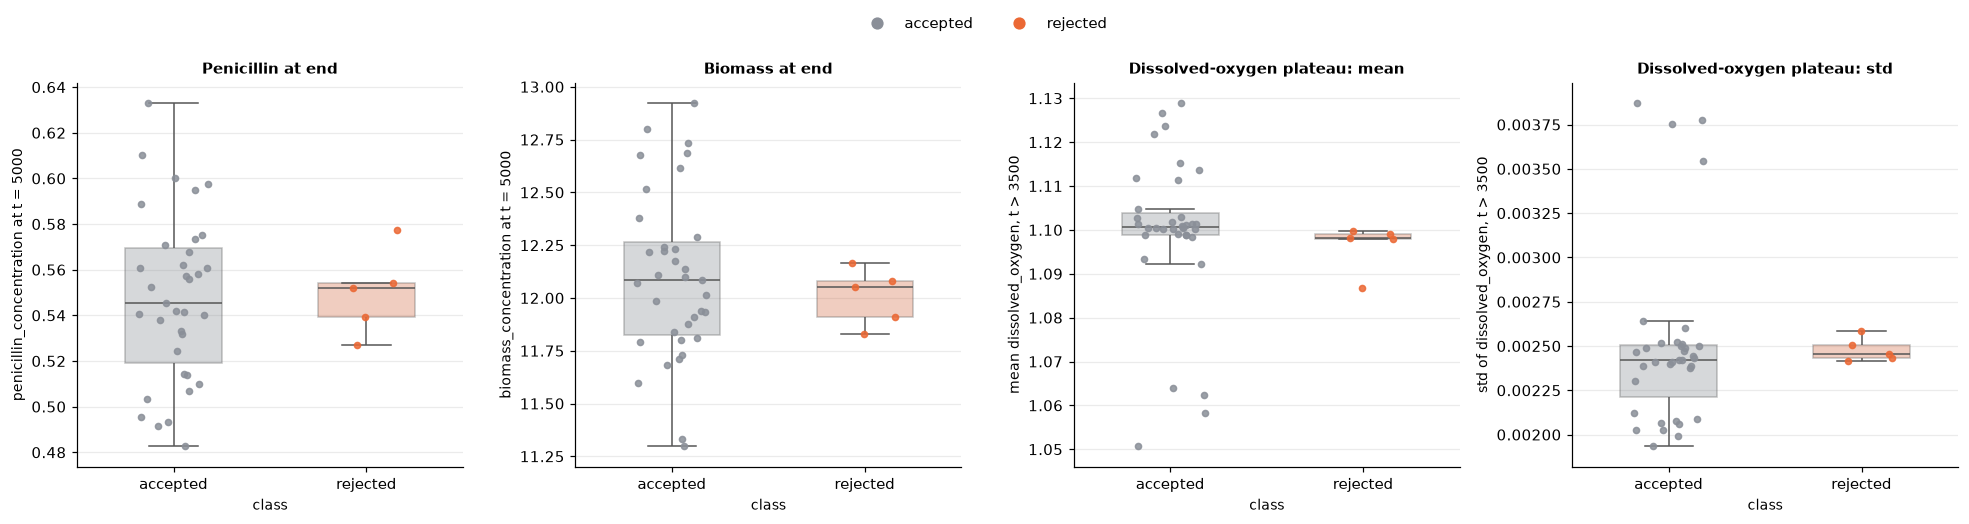

In [16]:
plat=pd.DataFrame({"do_plateau_mean":W["dissolved_oxygen"].loc[:,3500:].mean(axis=1),"do_plateau_std":W["dissolved_oxygen"].loc[:,3500:].std(axis=1)})
fig,axs=plt.subplots(1,4,figsize=(18,4.4))
for ax,(s,name,yl) in zip(axs,[(end["penicillin_concentration"],"Penicillin at end","penicillin_concentration at t = 5000"),(end["biomass_concentration"],"Biomass at end","biomass_concentration at t = 5000"),
                               (plat.do_plateau_mean,"Dissolved-oxygen plateau: mean","mean dissolved_oxygen, t > 3500"),(plat.do_plateau_std,"Dissolved-oxygen plateau: std","std of dissolved_oxygen, t > 3500")]):
    class_box(ax,s.values,yc,yl); ax.set_title(name)
top_legend(fig,CLASS_LEG); plt.tight_layout(); plt.show()

### 12.3 Does the aeration drop (t = 500–1250) leave a mark on other variables?
For every variable and timestep, a batch's **z-score = (value − median of accepted batches) / std of accepted batches**. Rejected batches are compared with all 35 accepted ones; each accepted batch is compared with the *other* 34 (leave-one-out), so we know how large a deviation is normal for a batch that is fine. What matters is the **change in z between the baseline before the window (t = 1–499) and the window (t = 500–1250)**. Variables that are zero for every batch in the window (`feed_rate`, `acid_flow`) are skipped.

In [17]:
WIN=(500,1250); PRE=(1,499); AFTER=(1251,1700)
Vz=[v for v in V if W[v].loc[:,WIN[0]:WIN[1]].std().max()>0]   # variables with any spread inside the window
def zts(v,b,ref):
    R=W[v].loc[ref]; return (W[v].loc[b]-R.median())/R.std().replace(0,np.nan)
Z={v:pd.concat([zts(v,b,ACCB if b in REJB else [a for a in ACCB if a!=b]).rename(b) for b in ids],axis=1).T for v in Vz}
mz=lambda z,a,b: z.loc[:,a:b].mean(axis=1)
chg={v:mz(Z[v],*WIN)-mz(Z[v],*PRE) for v in Vz}          # change in z: window minus pre-window baseline
aft={v:mz(Z[v],*AFTER)-mz(Z[v],*PRE) for v in Vz}
rows=[]
for v in Vz:
    c=chg[v]; a=c[ACCB].abs(); r=c[REJB]
    rows.append(dict(variable=v,rej_mean_change=r.mean(),rej_all_same_sign=bool((r>0).all() or (r<0).all()),rej_max_abs=r.abs().max(),acc_LOO_p95_abs=a.quantile(.95),acc_LOO_max_abs=a.max(),
                     rej_beyond_every_accepted=int((r.abs()>a.max()).sum()),rej_after_window_mean_change=aft[v][REJB].mean()))
T=pd.DataFrame(rows).set_index("variable").sort_values("rej_max_abs",ascending=False)
display(T.style.format({c:"{:.2f}" for c in T.columns if T[c].dtype==float}).background_gradient(subset=["rej_max_abs"],cmap="Oranges"))

,rej_mean_change,rej_all_same_sign,rej_max_abs,acc_LOO_p95_abs,acc_LOO_max_abs,rej_beyond_every_accepted,rej_after_window_mean_change
variable,,,,,,,
aeration_rate,-2.18,True,2.42,0.01,0.01,5,0.01
agitator_power,-0.08,False,1.05,1.00,1.49,0,-0.09
dissolved_oxygen,-0.76,True,0.93,0.61,0.81,2,-0.09
feed_temperature,-0.13,True,0.29,0.88,1.26,0,-0.58
ph,0.03,False,0.27,0.91,1.07,0,-0.04
substrate_concentration,-0.09,False,0.26,0.54,0.71,0,-0.17
dissolved_co2,0.01,False,0.21,0.57,0.65,0,0.01
base_flow,-0.02,True,0.03,0.03,0.03,0,-0.01
water_flow_rate,0.00,False,0.01,0.08,0.09,0,0.01


**Change in z during the drop, per rejected batch.** Left: red = the variable moved up, blue = down (in accepted-spread units) relative to the batch's own baseline. Right: size of that change for each rejected batch (markers) vs. what accepted batches show by chance (grey bar = 95th percentile, black tick = maximum). A marker far right of the tick = a real effect.

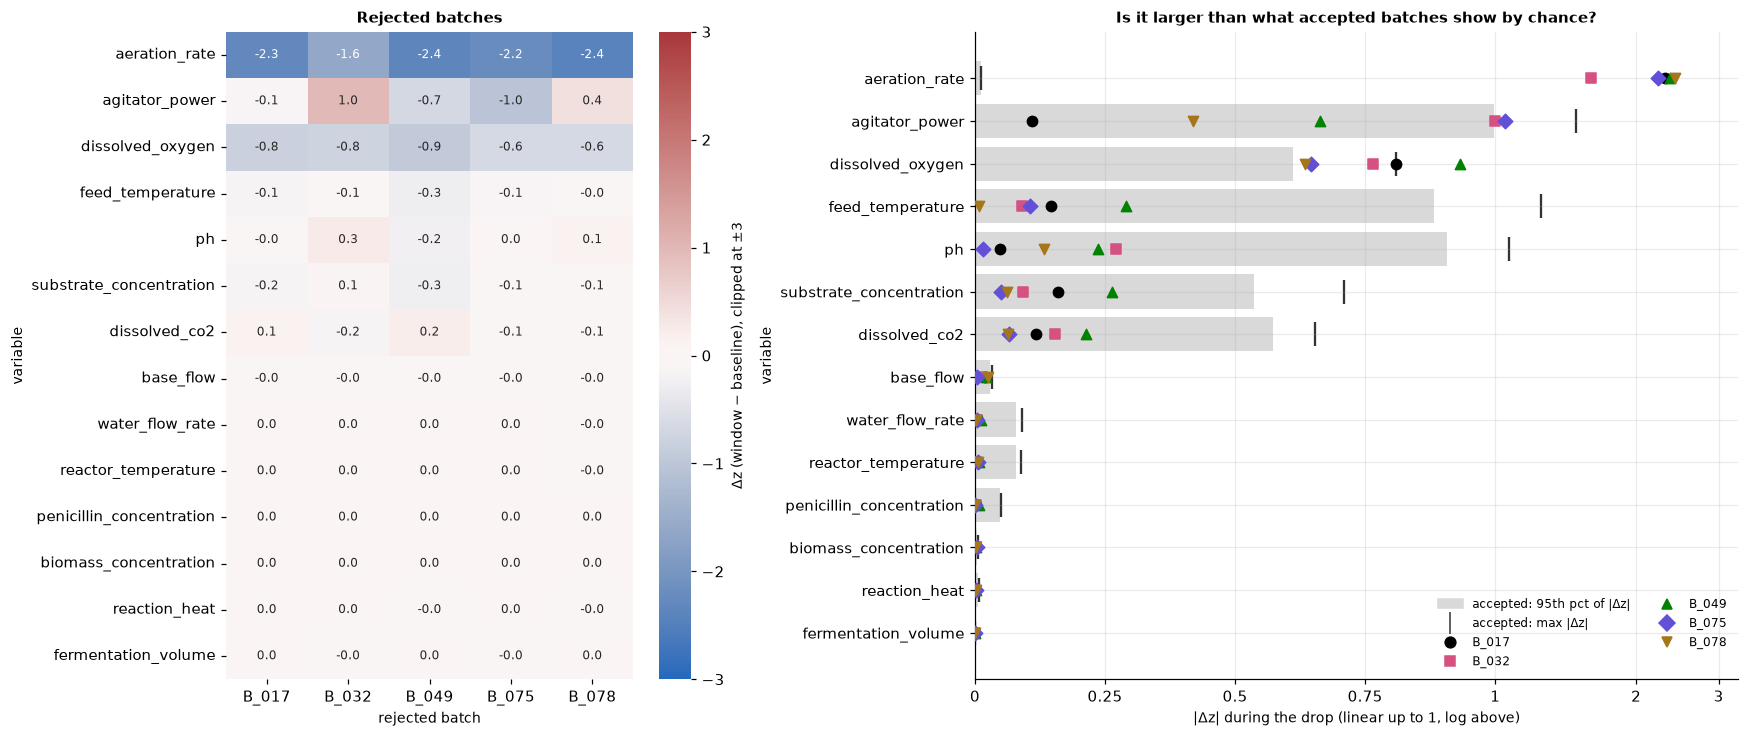

In [18]:
order=list(T.index); H=pd.DataFrame({b:[chg[v][b] for v in order] for b in REJB},index=order)
fig,ax=plt.subplots(1,2,figsize=(16,6.8),gridspec_kw=dict(width_ratios=[1,1.5]))
sns.heatmap(H,cmap="vlag",center=0,vmin=-3,vmax=3,annot=True,fmt=".1f",annot_kws=dict(size=8),ax=ax[0],cbar_kws=dict(label="Δz (window − baseline), clipped at ±3"))
ax[0].grid(False); ax[0].set(title="Rejected batches",xlabel="rejected batch",ylabel="variable")
y_=np.arange(len(order))[::-1]
ax[1].barh(y_,T.acc_LOO_p95_abs,color="#d9d9d9"); ax[1].scatter(T.acc_LOO_max_abs,y_,marker="|",s=250,color=INK)
for b in REJB: ax[1].scatter(H[b].abs(),y_,color=RS[b]["color"],marker=RS[b]["marker"],s=45,zorder=5)
ax[1].set_yticks(y_,order); ax[1].set_xscale("symlog",linthresh=1); ax[1].set_xticks([0,.25,.5,.75,1,2,3]); ax[1].set_xlim(0,3.3); ax[1].xaxis.set_major_formatter(PLAIN); ax[1].set(xlabel="|Δz| during the drop (linear up to 1, log above)",ylabel="variable",title="Is it larger than what accepted batches show by chance?")
ax[1].legend(handles=[patch("#d9d9d9","accepted: 95th pct of |Δz|",a=1),Line2D([],[],marker="|",ls="",color=INK,markersize=14,label="accepted: max |Δz|")]+[dot(RS[b]["color"],b,RS[b]["marker"]) for b in REJB],fontsize=8,ncol=2,loc="lower right")
plt.tight_layout(); plt.show()

**z-score of each variable over time** (first 2200 timesteps). Grey lines = accepted batches (each vs. the others), coloured = rejected, yellow = aeration-drop window. Curves are smoothed (25-step moving average) so level shifts are visible through the noise.

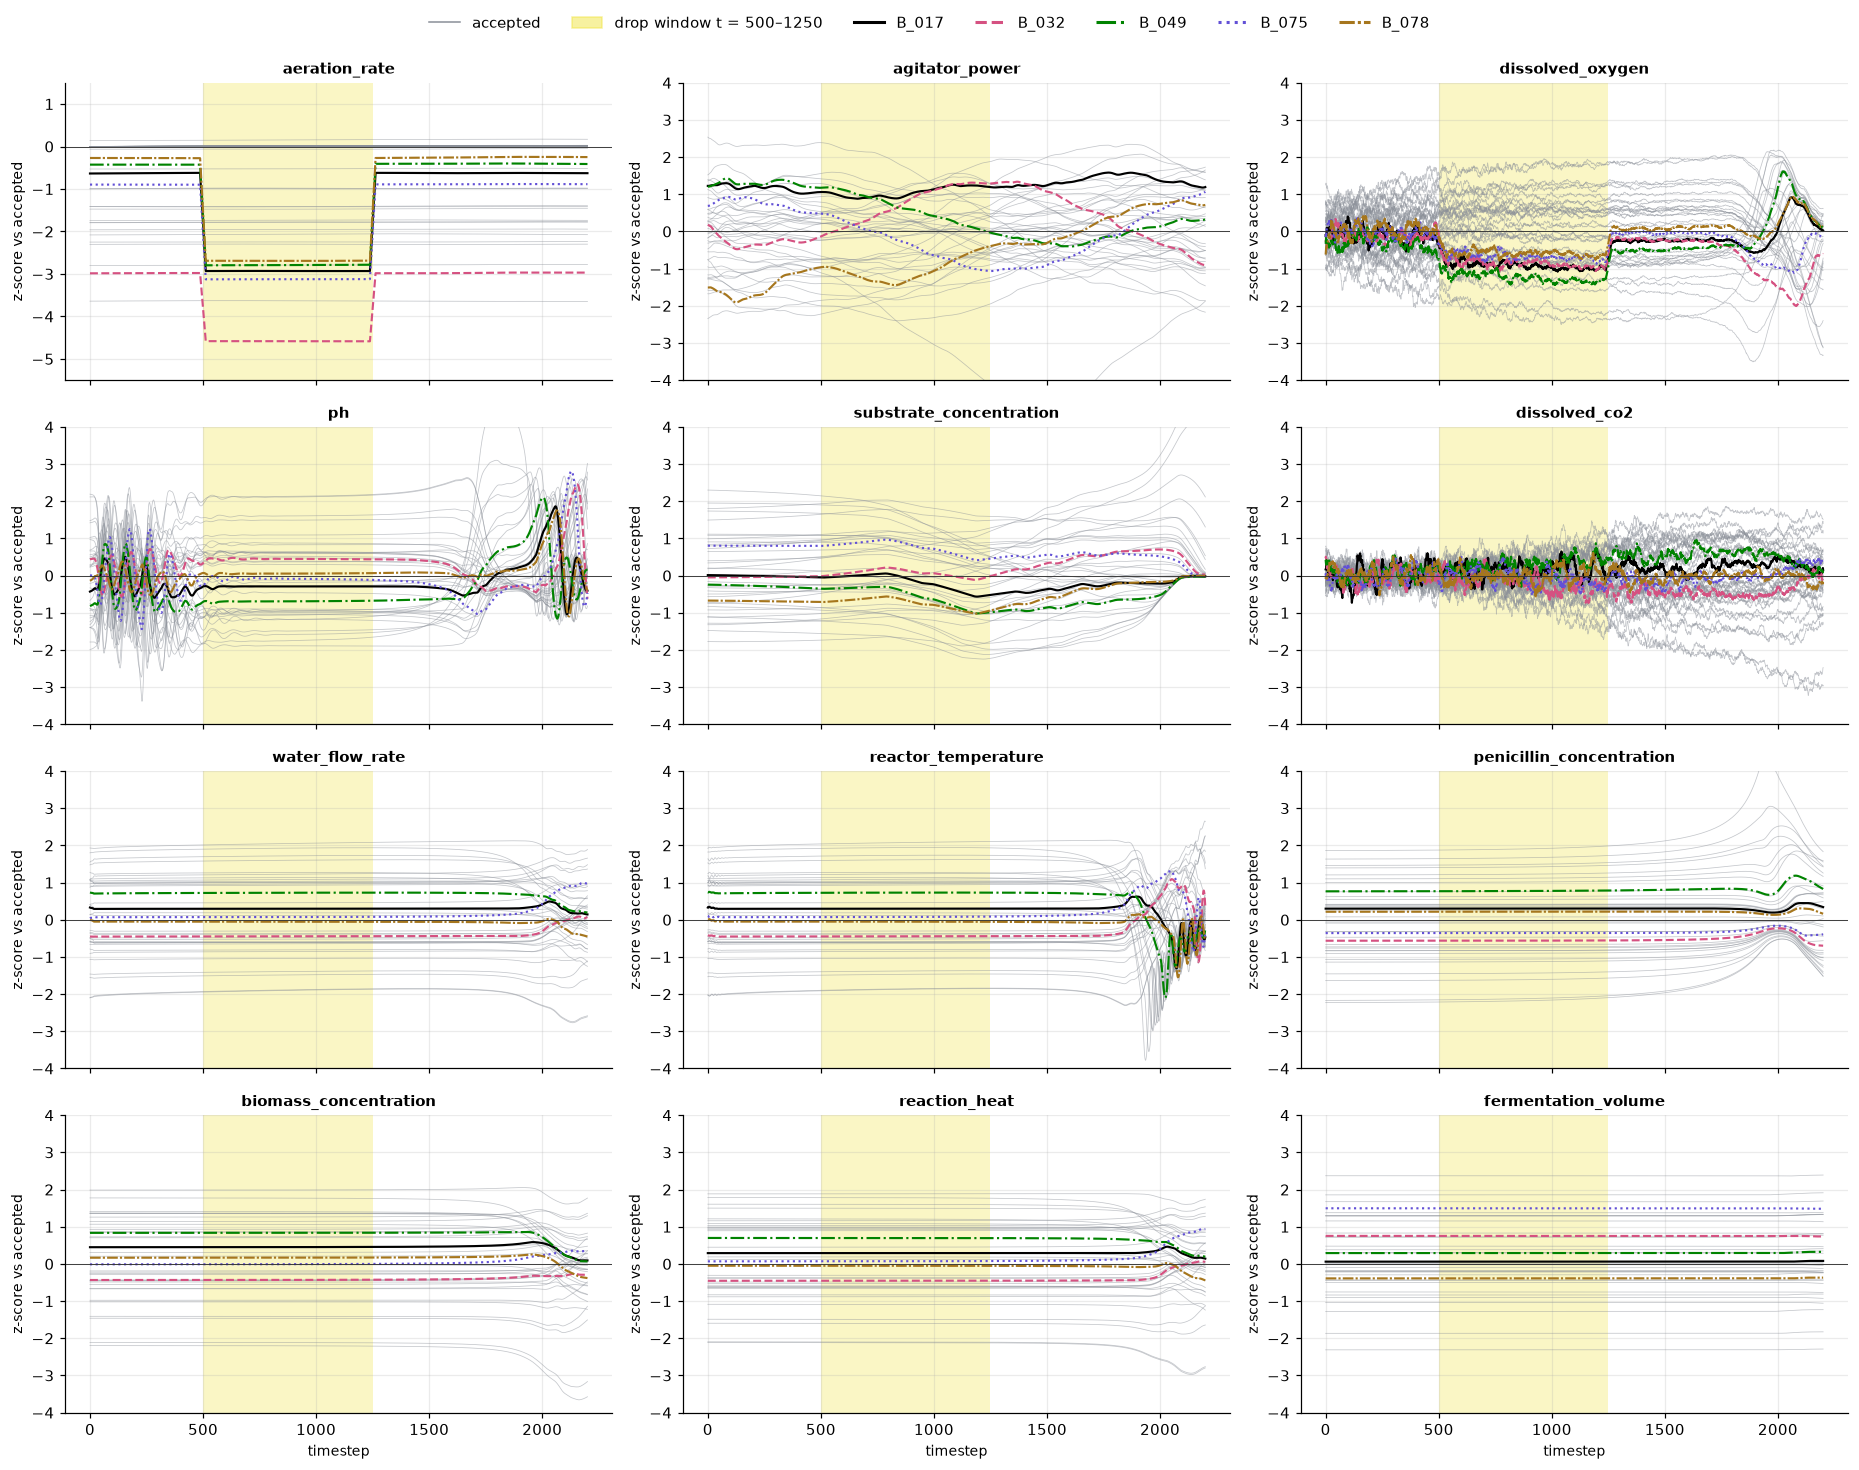

In [19]:
show=[v for v in order if v in("aeration_rate","dissolved_oxygen","biomass_concentration","dissolved_co2","substrate_concentration","penicillin_concentration","ph","reactor_temperature","reaction_heat","water_flow_rate","fermentation_volume","agitator_power")]
fig,axs=plt.subplots(4,3,figsize=(17,13),sharex=True)
for ax,v in zip(axs.ravel(),show):
    sm_=Z[v].T.rolling(25,center=True,min_periods=1).mean().T.loc[:,:2200]
    for b in ACCB: ax.plot(sm_.columns,sm_.loc[b],color=ACC,lw=.5,alpha=.5)
    for b in REJB: ax.plot(sm_.columns,sm_.loc[b],color=RS[b]["color"],ls=RS[b]["ls"],lw=1.4)
    ax.axvspan(*WIN,color=WIN_COL,alpha=.3,lw=0); ax.axhline(0,color=INK,lw=.6); ax.set_title(v); ax.set_ylim(-4,4) if v!="aeration_rate" else ax.set_ylim(-5.5,1.5)
    ax.set_ylabel("z-score vs accepted")
for ax in axs[-1]: ax.set_xlabel("timestep")
top_legend(fig,[line(ACC,"accepted",lw=1),patch(WIN_COL,"drop window t = 500–1250",a=.5)]+REJ_LEG,ncol=7)
plt.tight_layout(); plt.show()

**The same in raw units** for six key variables. All curves smoothed (25-step moving average). Grey band = accepted median ± 2 std, grey dashed line = accepted median, coloured = rejected batches, yellow = drop window.

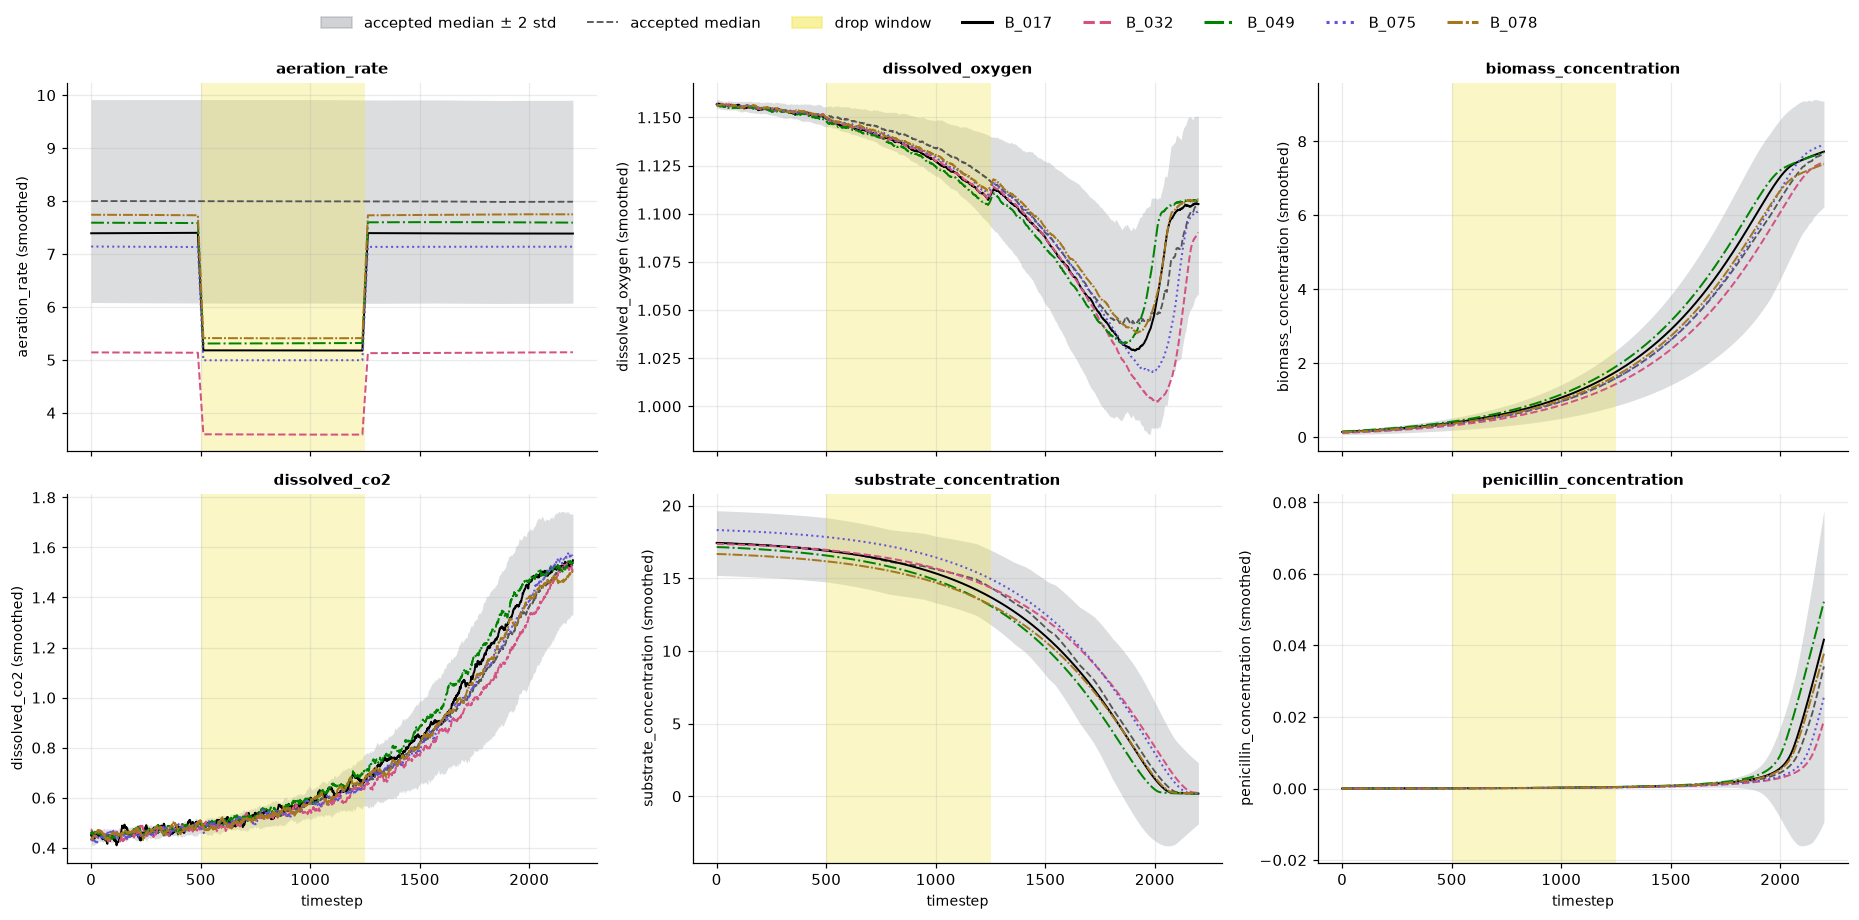

,DO mean in window,accepted std (batch means)
accepted median,1.1378,0.0061
B_017,1.1322,0.0061
B_032,1.1325,0.0061
B_049,1.1301,0.0061
B_075,1.1338,0.0061
B_078,1.1344,0.0061


DO – step-to-step noise inside window (std of first difference): rejected 0.00267–0.00290 | accepted 0.00262–0.00299 (median 0.00280)


In [20]:
fig,axs=plt.subplots(2,3,figsize=(17,8),sharex=True)
for ax,v in zip(axs.ravel(),["aeration_rate","dissolved_oxygen","biomass_concentration","dissolved_co2","substrate_concentration","penicillin_concentration"]):
    A_=W[v].loc[ACCB].T.rolling(25,center=True,min_periods=1).mean().T; m,s=A_.median(),A_.std(); sl=slice(0,2200)
    ax.fill_between(m.index[sl],(m-2*s)[sl],(m+2*s)[sl],color=ACC,alpha=.3,lw=0); ax.plot(m.index[sl],m[sl],lw=1.2,**MED_KW)
    for b in REJB: ax.plot(W[v].columns[sl],W[v].loc[b].rolling(25,center=True,min_periods=1).mean()[sl],color=RS[b]["color"],ls=RS[b]["ls"],lw=1.3)
    ax.axvspan(*WIN,color=WIN_COL,alpha=.3,lw=0); ax.set(title=v,ylabel=f"{v} (smoothed)")
for ax in axs[-1]: ax.set_xlabel("timestep")
top_legend(fig,[patch(ACC,"accepted median ± 2 std"),line(label="accepted median",lw=1.2,**MED_KW),patch(WIN_COL,"drop window",a=.5)]+REJ_LEG,ncol=8)
plt.tight_layout(); plt.show()
dd=pd.DataFrame({"accepted median":W["dissolved_oxygen"].loc[ACCB,WIN[0]:WIN[1]].mean(axis=1).median(),**{b:W["dissolved_oxygen"].loc[b,WIN[0]:WIN[1]].mean() for b in REJB}},index=["DO mean in window"]).T
dd["accepted std (batch means)"]=W["dissolved_oxygen"].loc[ACCB,WIN[0]:WIN[1]].mean(axis=1).std(); display(dd.round(4))
sn=W["dissolved_oxygen"].loc[:,WIN[0]:WIN[1]].diff(axis=1).std(axis=1)
print(f"DO – step-to-step noise inside window (std of first difference): rejected {sn[REJB].min():.5f}–{sn[REJB].max():.5f} | accepted {sn[ACCB].min():.5f}–{sn[ACCB].max():.5f} (median {sn[ACCB].median():.5f})")